In [1]:
import os
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "US_Accidents_March23.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "sobhanmoosavi/us-accidents",
  file_path,
  pandas_kwargs={"dtype": {
      **{c: "category" for c in ["Source", "State", "Country", "Timezone",
          "Airport_Code", "Weather_Condition", "Wind_Direction", "Sunrise_Sunset",
          "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]},
      **{c: "float32" for c in ["End_Lat", "End_Lng", "Distance(mi)",
          "Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
          "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]},
      "Severity": "int8",
  }},
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("5 pierwszych rekordów:", df.head())

c:\Users\lucri\Desktop\SEM2MGR\ZSSI REPO\ZSSI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\523636962.py:11: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


5 pierwszych rekordów:     ID   Source  Severity           Start_Time             End_Time  \
0  A-1  Source2         3  2016-02-08 05:46:00  2016-02-08 11:00:00   
1  A-2  Source2         2  2016-02-08 06:07:59  2016-02-08 06:37:59   
2  A-3  Source2         2  2016-02-08 06:49:27  2016-02-08 07:19:27   
3  A-4  Source2         3  2016-02-08 07:23:34  2016-02-08 07:53:34   
4  A-5  Source2         2  2016-02-08 07:39:07  2016-02-08 08:09:07   

   Start_Lat  Start_Lng  End_Lat  End_Lng  Distance(mi)  ... Roundabout  \
0  39.865147 -84.058723      NaN      NaN          0.01  ...      False   
1  39.928059 -82.831184      NaN      NaN          0.01  ...      False   
2  39.063148 -84.032608      NaN      NaN          0.01  ...      False   
3  39.747753 -84.205582      NaN      NaN          0.01  ...      False   
4  39.627781 -84.188354      NaN      NaN          0.01  ...      False   

  Station   Stop Traffic_Calming Traffic_Signal Turning_Loop Sunrise_Sunset  \
0   False  False    

# Analiza wypadków drogowych w USA

# Import wymaganych bibliotek

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as mn
import plotly.graph_objects as go

# Przygotowanie danych

### Informacje

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7728394 entries, 0 to 7728393
Data columns (total 46 columns):
 #   Column                 Dtype   
---  ------                 -----   
 0   ID                     str     
 1   Source                 category
 2   Severity               int8    
 3   Start_Time             str     
 4   End_Time               str     
 5   Start_Lat              float64 
 6   Start_Lng              float64 
 7   End_Lat                float32 
 8   End_Lng                float32 
 9   Distance(mi)           float32 
 10  Description            str     
 11  Street                 str     
 12  City                   str     
 13  County                 str     
 14  State                  category
 15  Zipcode                str     
 16  Country                category
 17  Timezone               category
 18  Airport_Code           category
 19  Weather_Timestamp      str     
 20  Temperature(F)         float32 
 21  Wind_Chill(F)          float32 
 22  Humid

#### Kolumny ramki danych

In [4]:
df.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight'],
      dtype='str')

#### Statystyki opisowe każdej kolumny numerycznej

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Severity,7728394.0,2.212384,0.487531,1.000000,2.000000,2.000000,2.000000,4.000000
Start_Lat,7728394.0,36.201195,5.076079,24.554800,33.399631,35.823974,40.084959,49.002201
Start_Lng,7728394.0,-94.702545,17.391756,-124.623833,-117.219396,-87.766616,-80.353676,-67.113167
End_Lat,4325632.0,36.261829,5.272904,24.566013,33.462070,36.183495,40.178921,49.075001
End_Lng,4325632.0,-95.725563,18.107927,-124.545746,-117.754341,-88.027893,-80.247086,-67.109245
Distance(mi),7728394.0,0.561842,1.776811,0.000000,0.000000,0.030000,0.464000,441.750000
Temperature(F),7564541.0,61.663288,19.013653,-89.000000,49.000000,64.000000,76.000000,207.000000
Wind_Chill(F),5729375.0,58.251045,22.389832,-89.000000,43.000000,62.000000,75.000000,207.000000
Humidity(%),7554250.0,64.831039,22.820969,1.000000,48.000000,67.000000,84.000000,100.000000
Pressure(in),7587715.0,29.538986,1.006190,0.000000,29.370001,29.860001,30.030001,58.630001


**Obserwacje.** Zbiór zawiera 7 728 394 rekordy i 46 atrybutów. Rozkład `Distance(mi)` jest silnie prawostronnie skośny: mediana wynosi 0,03 mili, a średnia około 0,56 mili. Maksima temperatury 207°F, prędkości wiatru 1087 mph oraz ciśnienia 58,63 in wymagają kontroli wiarygodności; sama obecność ekstremum nie uzasadnia jednak usuwania wszystkich wartości odstających.

#### Kolumny numeryczne do analizy

In [6]:
# Dane typu int, float i boolean
print(df.count(numeric_only=True))
print("Łączna liczba kolumn numerycznych:", len(df.count(numeric_only=True)))

Severity             7728394
Start_Lat            7728394
Start_Lng            7728394
End_Lat              4325632
End_Lng              4325632
Distance(mi)         7728394
Temperature(F)       7564541
Wind_Chill(F)        5729375
Humidity(%)          7554250
Pressure(in)         7587715
Visibility(mi)       7551296
Wind_Speed(mph)      7157161
Precipitation(in)    5524808
Amenity              7728394
Bump                 7728394
Crossing             7728394
Give_Way             7728394
Junction             7728394
No_Exit              7728394
Railway              7728394
Roundabout           7728394
Station              7728394
Stop                 7728394
Traffic_Calming      7728394
Traffic_Signal       7728394
Turning_Loop         7728394
dtype: int64
Łączna liczba kolumn numerycznych: 26


### Procent brakujących wartości

In [7]:
missing_values = df.isna().sum().sort_values(ascending=False)
missing_percentage = missing_values[missing_values!=0]/len(df)*100
print(" Procent brakujących wartości \n", missing_percentage)

 Procent brakujących wartości 
 End_Lng                  44.029355
End_Lat                  44.029355
Precipitation(in)        28.512858
Wind_Chill(F)            25.865904
Wind_Speed(mph)           7.391355
Visibility(mi)            2.291524
Wind_Direction            2.267043
Humidity(%)               2.253301
Weather_Condition         2.244438
Temperature(F)            2.120143
Pressure(in)              1.820288
Weather_Timestamp         1.555666
Sunrise_Sunset            0.300787
Civil_Twilight            0.300787
Astronomical_Twilight     0.300787
Nautical_Twilight         0.300787
Airport_Code              0.292881
Street                    0.140637
Timezone                  0.101030
Zipcode                   0.024779
City                      0.003274
Description               0.000065
dtype: float64


**Wnioski o brakach.** Największe braki dotyczą `End_Lat` i `End_Lng` (po 44,03%), opadów (28,51%) i temperatury odczuwalnej (25,87%). Brak pomiaru opadów nie oznacza braku opadów. Usuwanie wszystkich niekompletnych rekordów mogłoby silnie zmniejszyć zbiór; wpływ zastosowanego czyszczenia na klasy sprawdzamy w dalszej części EDA.

Uzyskanie listy kolumn zawierających wartości puste

In [8]:
null_cols = [i for i in df.columns if df[i].isnull().any()]
print(null_cols)

['End_Lat', 'End_Lng', 'Description', 'Street', 'City', 'Zipcode', 'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']


Sprawdzenie wzorca brakujących wartości w ramce danych

<Axes: >

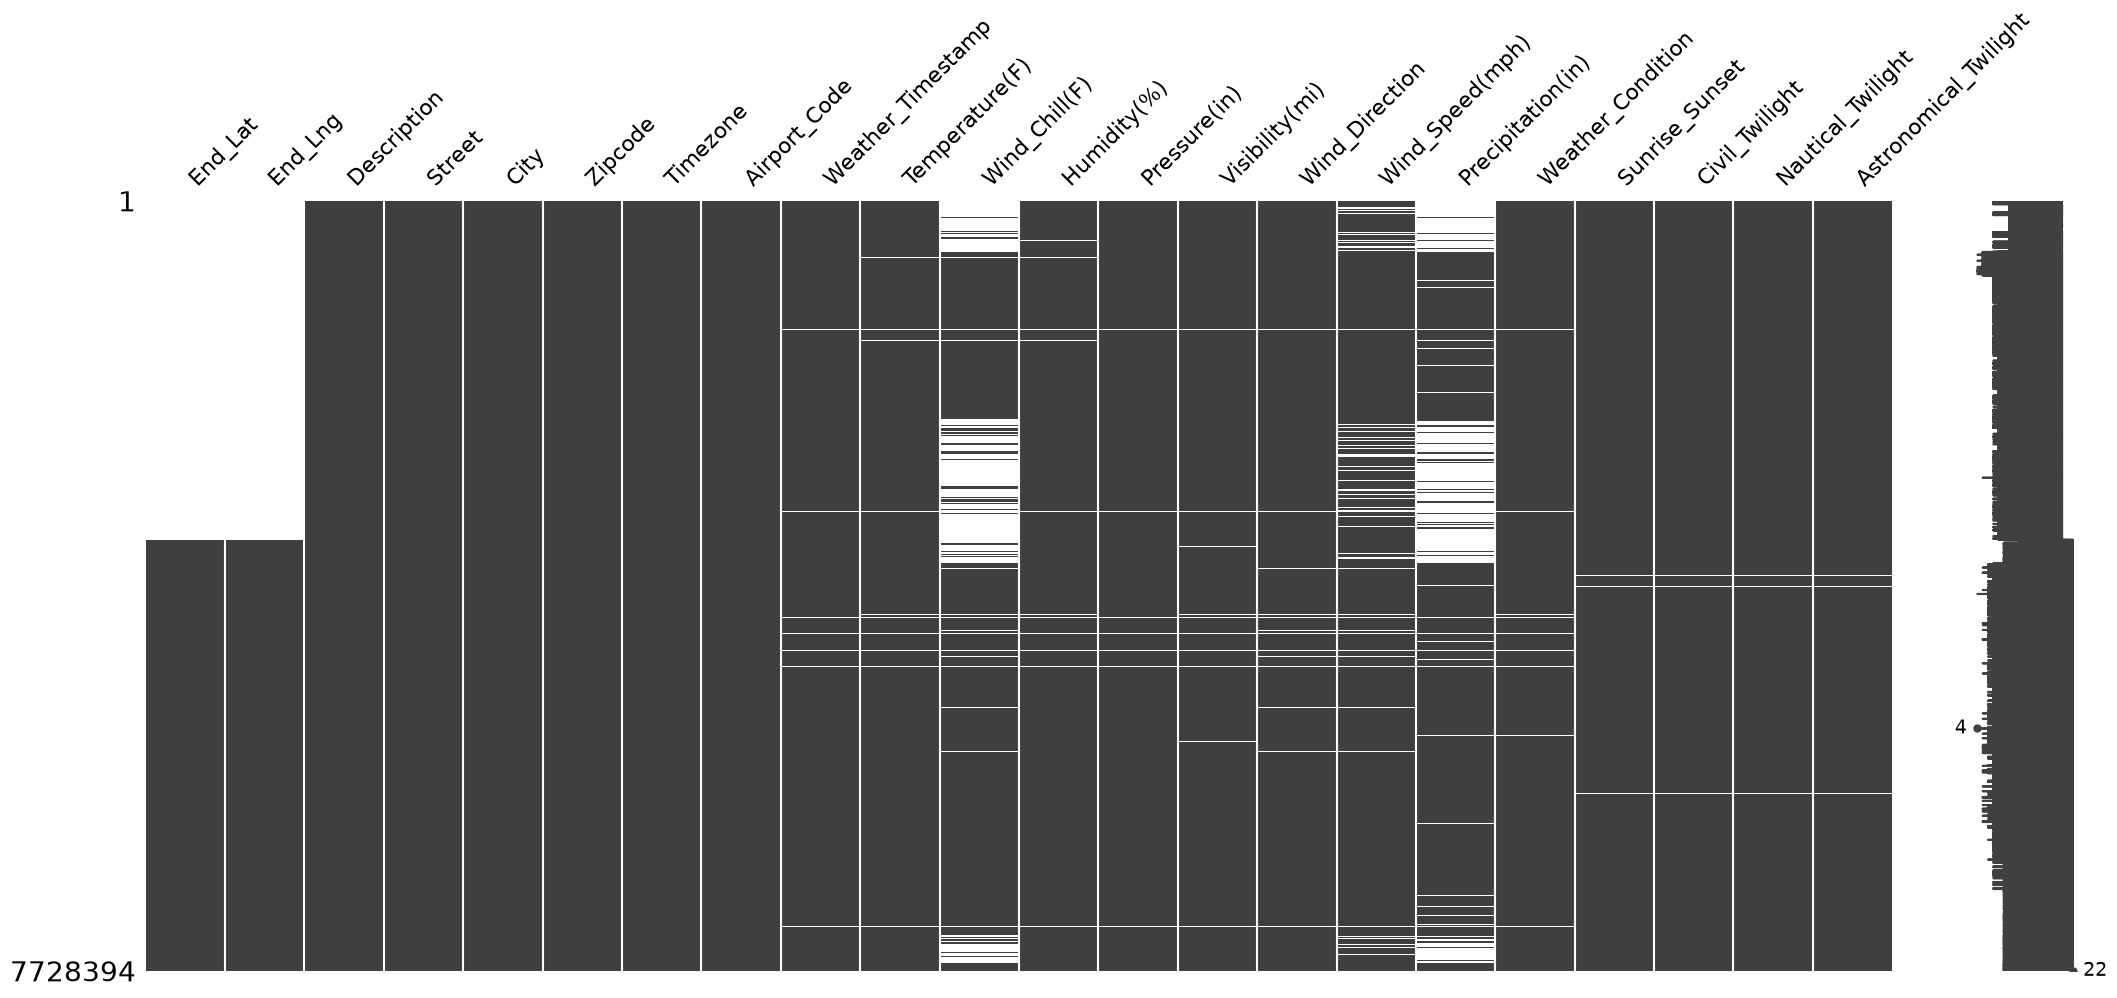

In [9]:
mn.matrix(df[null_cols])

Usunięcie kolumn [End_Lng, End_Lat] zawierających dużo brakujących wartości oraz wierszy z brakami w wybranych kolumnach

In [10]:
new_data_a = df.drop(columns=["End_Lng", "End_Lat"], axis=0)
new_data_b = new_data_a.dropna(subset = ['Visibility(mi)','Weather_Condition','Humidity(%)',
                                         'Temperature(F)','Wind_Direction','Pressure(in)',
                                         'Weather_Timestamp','Airport_Code','Timezone',
                                         'Zipcode','Sunrise_Sunset','Civil_Twilight',
                                         'Nautical_Twilight','Astronomical_Twilight',
                                         'City','Description'])

dataf = new_data_b.drop(columns = 'ID', axis=0)

### Usuwamy wiersze z brakującymi wartościami w wybranych kolumnach o niewielkim odsetku braków
### Dodatkowo braki w pozostałych pomiarach uzupełniamy średnią (tymczasowo)

In [11]:
dataf["Wind_Chill(F)"] = dataf['Wind_Chill(F)'].fillna(dataf['Wind_Chill(F)'].mean())
dataf["Precipitation(in)"] = dataf['Precipitation(in)'].fillna(dataf['Precipitation(in)'].mean())
dataf["Wind_Speed(mph)"] = dataf['Wind_Speed(mph)'].fillna(dataf['Wind_Speed(mph)'].mean())

In [12]:
final_data = dataf.reindex(copy=True)
final_data.head()

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\1636506883.py:1: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  final_data = dataf.reindex(copy=True)


,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),Description,Street,City,...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,0.01,Right lane blocked due to accident on I-70 Eas...,I-70 E,Dayton,...,False,False,False,False,False,False,Night,Night,Night,Night
1,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,0.01,Accident on Brice Rd at Tussing Rd. Expect del...,Brice Rd,Reynoldsburg,...,False,False,False,False,False,False,Night,Night,Night,Day
2,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,0.01,Accident on OH-32 State Route 32 Westbound at ...,State Route 32,Williamsburg,...,False,False,False,False,True,False,Night,Night,Day,Day
3,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,0.01,Accident on I-75 Southbound at Exits 52 52B US...,I-75 S,Dayton,...,False,False,False,False,False,False,Night,Day,Day,Day
4,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,0.01,Accident on McEwen Rd at OH-725 Miamisburg Cen...,Miamisburg Centerville Rd,Dayton,...,False,False,False,False,True,False,Day,Day,Day,Day


# Analiza wypadków według lokalizacji

In [13]:
print("Kody stanów: ", final_data.State.unique())
print("Łączna liczba stanów w zbiorze danych: ", len(final_data.State.unique()))

Kody stanów:  ['OH', 'WV', 'CA', 'FL', 'GA', ..., 'WY', 'ID', 'ND', 'MT', 'SD']
Length: 49
Categories (49, str): ['AL', 'AR', 'AZ', 'CA', ..., 'WA', 'WI', 'WV', 'WY']
Łączna liczba stanów w zbiorze danych:  49


C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\3160576481.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="State", data=final_data, orient = 'v', palette = "crest_r", order = final_data['State'].value_counts().index)


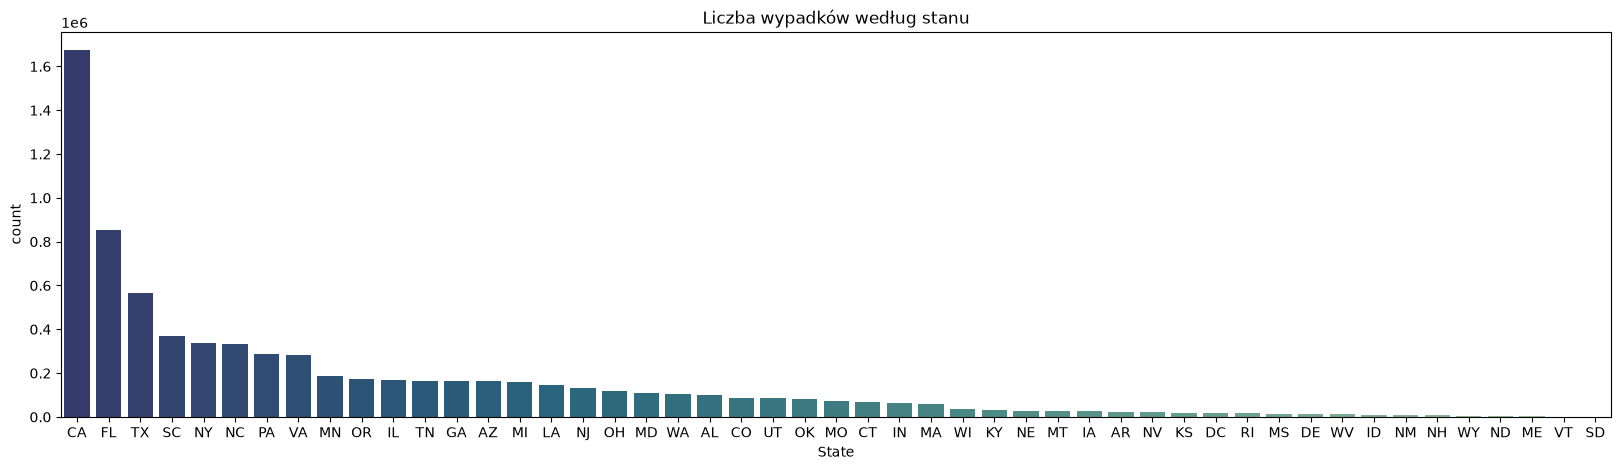

In [14]:
fig, ax = plt.subplots(figsize = (20,5))
c = sns.countplot(x="State", data=final_data, orient = 'v', palette = "crest_r", order = final_data['State'].value_counts().index)
c.set_title("Liczba wypadków według stanu");

In [15]:
print("Nazwy miast: ", final_data.City.unique())
print("Łączna liczba miast w zbiorze danych: ", len(final_data.City.unique()))

Nazwy miast:  <StringArray>
[                      'Dayton',                 'Reynoldsburg',
                 'Williamsburg',                  'Westerville',
                     'Columbus',                   'Miamisburg',
                    'Johnstown',                       'Dublin',
             'Canal Winchester',                      'Lebanon',
 ...
                      'Leadore',                   'Vallecitos',
                    'Guildhall',              'Sandy River Plt',
                       'Lublin',                     'Fairbank',
                    'Pond Eddy',                    'Ness City',
                   'Clarksdale', 'American Fork-Pleasant Grove']
Length: 12237, dtype: str
Łączna liczba miast w zbiorze danych:  12237


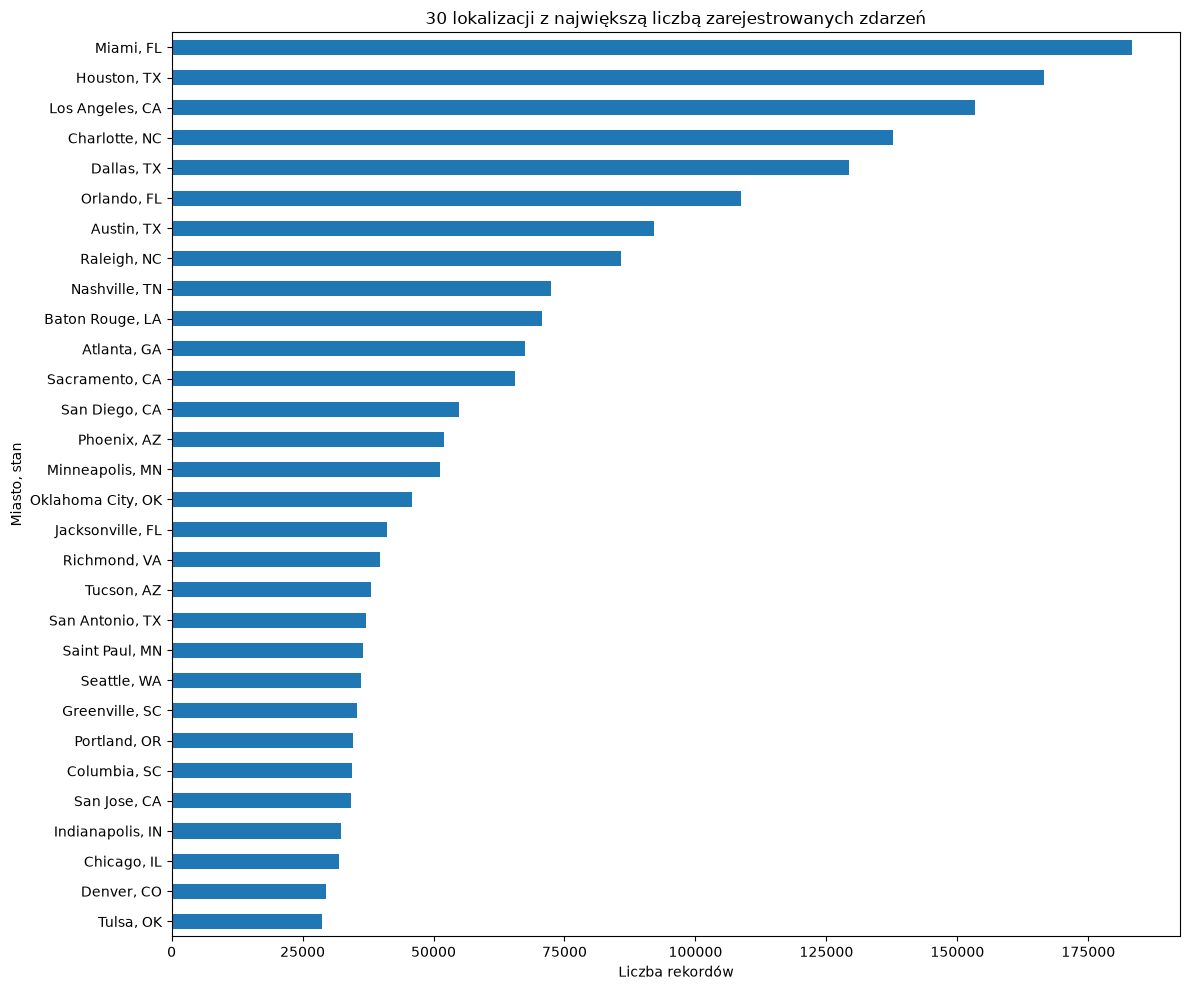

In [16]:
city_totals = final_data.groupby(['State', 'City'], observed=True).size().nlargest(30)
city_totals.index = [f'{city}, {state}' for state, city in city_totals.index]
city_totals.sort_values().plot.barh(figsize=(12, 10))
plt.title('30 lokalizacji z największą liczbą zarejestrowanych zdarzeń')
plt.xlabel('Liczba rekordów')
plt.ylabel('Miasto, stan')
plt.tight_layout()
plt.show()


**Obserwacje dotyczące lokalizacji.** Po czyszczeniu pozostało 49 różnych kodów `State` i 12 237 różnych nazw miast. Nazwa miasta nie jest jednoznacznym identyfikatorem lokalizacji, dlatego ranking uwzględnia również stan. Wśród pokazanych lokalizacji najwięcej rekordów ma Miami, następnie Houston i Los Angeles. Są to liczby zarejestrowanych zdarzeń, a nie wskaźniki ryzyka: nie uwzględniają liczby mieszkańców, natężenia ruchu ani kompletności rejestracji.

# Przygotowanie znaczników czasu

In [17]:
final_data.Start_Time = pd.to_datetime(final_data.Start_Time, format='mixed')
final_data.Start_Time[0]

Timestamp('2016-02-08 05:46:00')

## Podzbiory według czasu

In [18]:
final_data['Month'] = final_data['Start_Time'].dt.month
final_data['Year'] = final_data['Start_Time'].dt.year
final_data['Hour'] = final_data['Start_Time'].dt.hour
final_data['Weekday'] = final_data['Start_Time'].dt.day_of_week
#yearly data subset 
data_2016 = final_data[final_data.Start_Time.dt.year == 2016]
data_2017 = final_data[final_data.Start_Time.dt.year == 2017]
data_2018 = final_data[final_data.Start_Time.dt.year == 2018]
data_2019 = final_data[final_data.Start_Time.dt.year == 2019]
data_2020 = final_data[final_data.Start_Time.dt.year == 2020]
data_2021 = final_data[final_data.Start_Time.dt.year == 2021]
data_2022 = final_data[final_data.Start_Time.dt.year == 2022]
data_2023 = final_data[final_data.Start_Time.dt.year == 2023]
data_2017_2019 = final_data[(final_data["Year"] >= 2017) & (final_data["Year"] <= 2019)]

# Roczna analiza wypadków

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\3795043188.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Year", data=final_data, orient = 'v', palette = "crest")


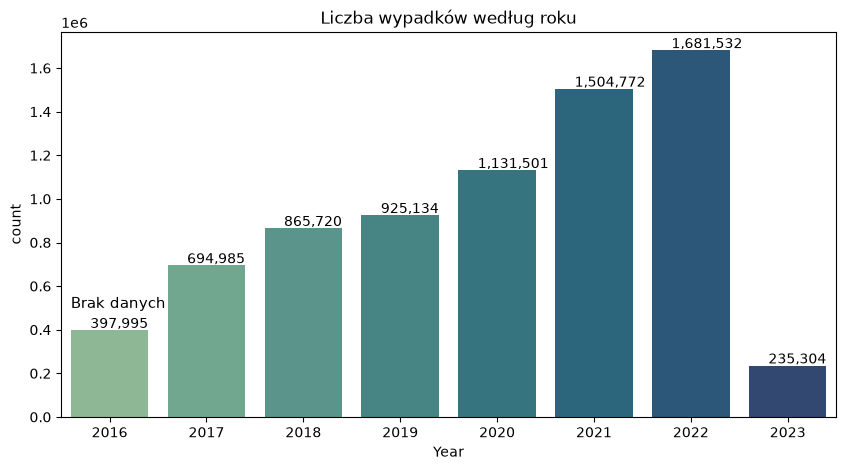

In [19]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Year", data=final_data, orient = 'v', palette = "crest")
plt.annotate('Brak danych',xy=(-0.4,500000), fontsize=11)
c.set_title("Liczba wypadków według roku")
for i in ax.patches:
    count = '{:,.0f}'.format(i.get_height())
    x = i.get_x()+i.get_width()-0.60
    y = i.get_height()+10000
    ax.annotate(count, (x, y))
plt.show()

# Miesięczna analiza wypadków

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2437316586.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Month", data=data_2016, orient = 'v', palette = "crest")


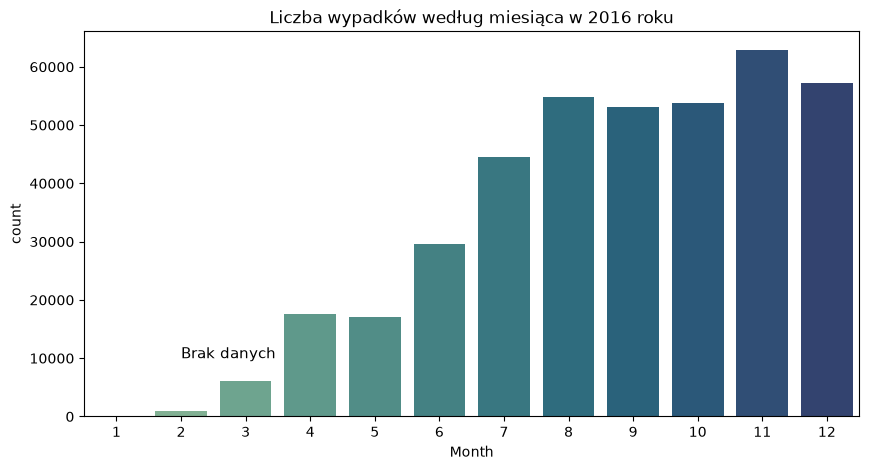

In [20]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Month", data=data_2016, orient = 'v', palette = "crest")
plt.annotate('Brak danych',xy=(1,10000), fontsize=11)
c.set_title("Liczba wypadków według miesiąca w 2016 roku")
plt.show()

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2353514459.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Month", data=data_2017_2019, orient = 'v', palette = "crest")


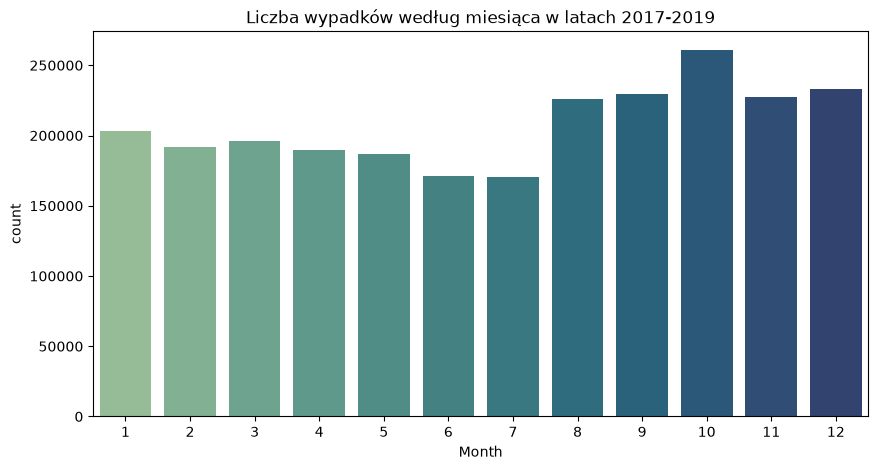

In [21]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Month", data=data_2017_2019, orient = 'v', palette = "crest")
c.set_title("Liczba wypadków według miesiąca w latach 2017-2019")
plt.show()

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\1672196103.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Month", data=data_2020, orient = 'v', palette = "crest")


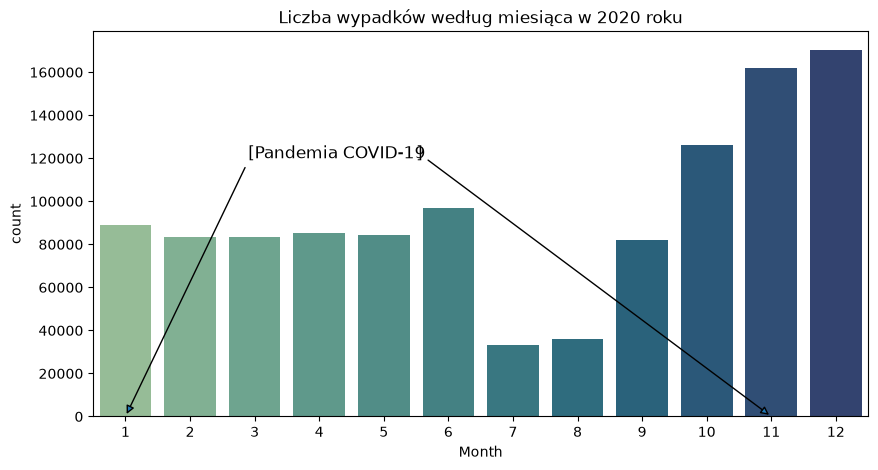

In [22]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Month", data=data_2020, orient = 'v', palette = "crest")
plt.annotate('Pandemia COVID-19',xy=(2,120000), fontsize=12)
plt.annotate("[",xy=(0,0),xytext=(1.9,120000),arrowprops={'arrowstyle':'-|>'}, fontsize=12)
plt.annotate("]",xy=(10,0),xytext=(4.5,120000),arrowprops={'arrowstyle':'-|>'}, fontsize=12)
c.set_title("Liczba wypadków według miesiąca w 2020 roku")
plt.show()

# Tygodniowa analiza wypadków

## Wszystkie tygodnie 2022 roku

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\1385715666.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x=data_2022.Start_Time.dt.isocalendar().week, data=data_2022, orient = 'v', palette = "crest")


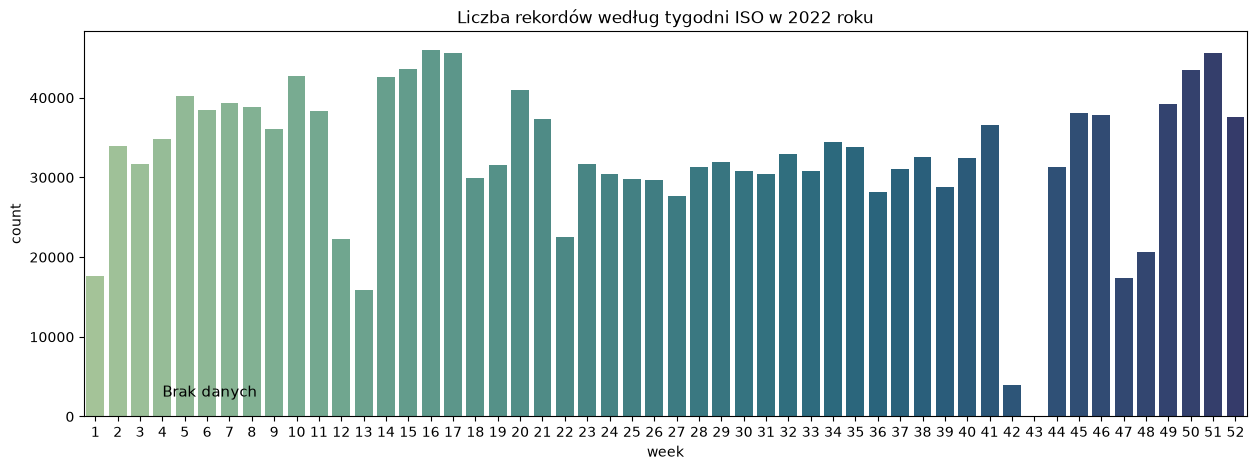

In [23]:
fig, ax = plt.subplots(figsize = (15,5))
c = sns.countplot(x=data_2022.Start_Time.dt.isocalendar().week, data=data_2022, orient = 'v', palette = "crest")
plt.annotate('Brak danych',xy=(3,2500), fontsize=11)
c.set_title("Liczba rekordów według tygodni ISO w 2022 roku")
plt.show()

## Wszystkie tygodnie w latach 2017-2019

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\955991545.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x=data_2017_2019.Start_Time.dt.isocalendar().week, data=data_2017_2019, orient = 'v', palette = "crest")


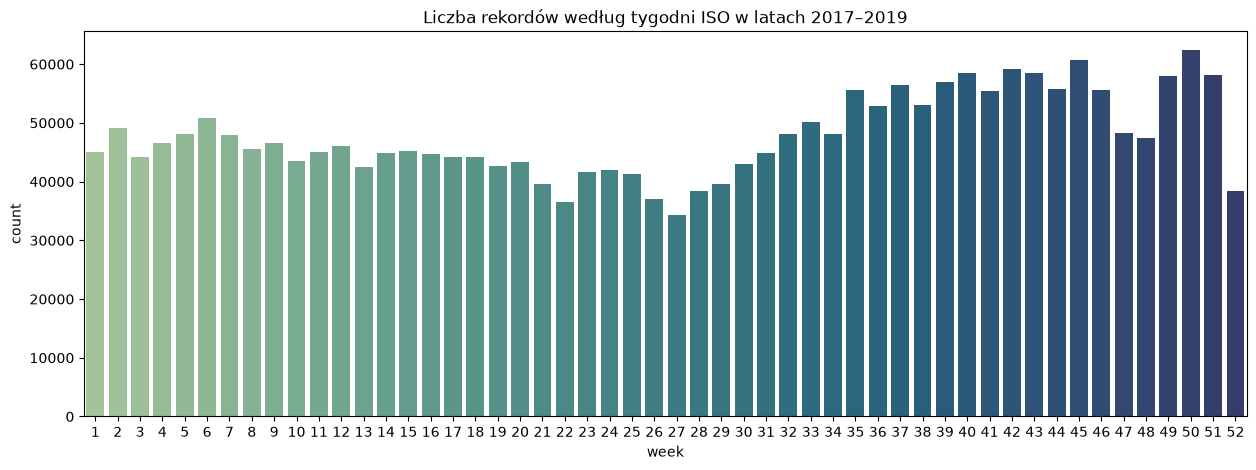

In [24]:
fig, ax = plt.subplots(figsize = (15,5))
c = sns.countplot(x=data_2017_2019.Start_Time.dt.isocalendar().week, data=data_2017_2019, orient = 'v', palette = "crest")
c.set_title("Liczba rekordów według tygodni ISO w latach 2017–2019")
plt.show()

## Dni tygodnia

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2578047313.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Weekday", data=final_data, orient = 'v', palette = "crest_r")


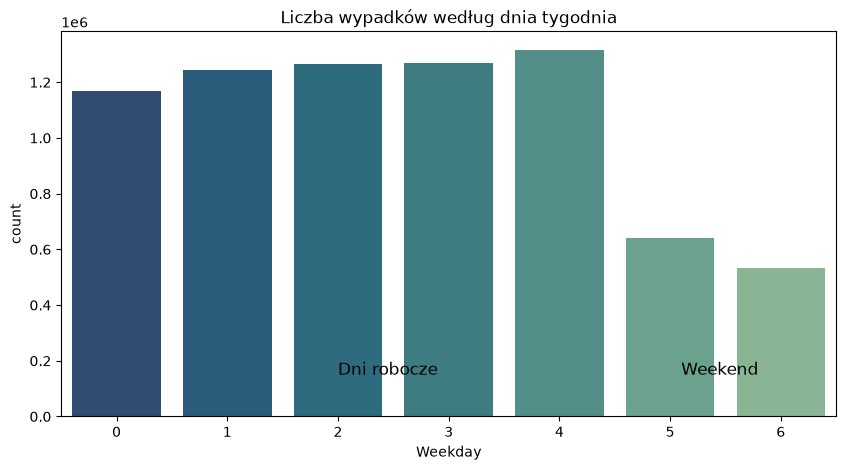

In [25]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Weekday", data=final_data, orient = 'v', palette = "crest_r")
plt.annotate('Dni robocze',xy=(2,150000), fontsize=12)
plt.annotate('Weekend',xy=(5.1,150000), fontsize=12)
c.set_title("Liczba wypadków według dnia tygodnia")
plt.show()

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2002071814.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Hour", data=final_data, orient = 'v', palette = "icefire_r")


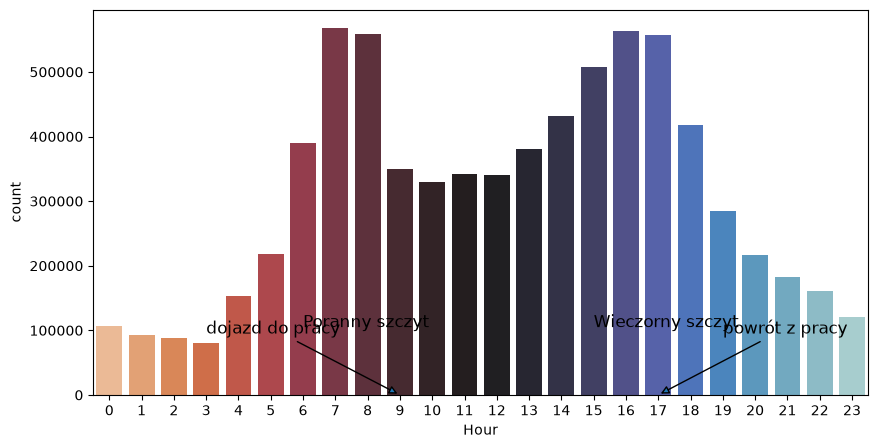

In [26]:
fig, ax = plt.subplots(figsize = (10,5))
sns.countplot(x="Hour", data=final_data, orient = 'v', palette = "icefire_r")
plt.annotate('Poranny szczyt',xy=(6,105000), fontsize=12)
plt.annotate('Wieczorny szczyt',xy=(15,105000), fontsize=12)
plt.annotate('dojazd do pracy',xy=(9,0),xytext=(3,95000),arrowprops={'arrowstyle':'-|>'}, fontsize=12)
plt.annotate('powrót z pracy',xy=(17,0),xytext=(19,95000),arrowprops={'arrowstyle':'-|>'}, fontsize=12)
plt.show()

## Analiza wypadków według stopnia ciężkości

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\3177534433.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c = sns.countplot(x="Severity", data=final_data, orient = 'v', palette = "crest_r")


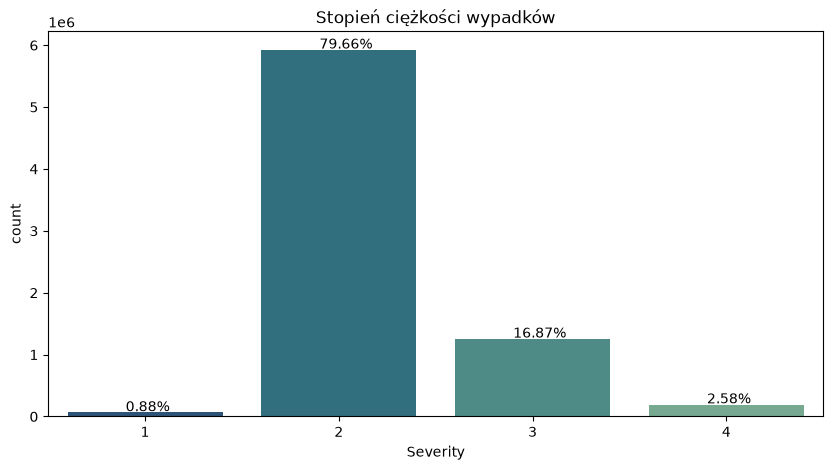

In [27]:
fig, ax = plt.subplots(figsize = (10,5))
c = sns.countplot(x="Severity", data=final_data, orient = 'v', palette = "crest_r")
c.set_title("Stopień ciężkości wypadków")
for i in ax.patches:
    count = "{:.2%}".format(i.get_height()/len(final_data.Severity))
    x = i.get_x()+i.get_width()-0.50
    y = i.get_height()+20000
    ax.annotate(count, (x, y))
plt.show()

**Wniosek o klasach.** W danych źródłowych klasa 2 obejmuje 79,67% rekordów, klasa 3 — 16,81%, klasa 4 — 2,65%, a klasa 1 — 0,87%. Jest to silnie niezbalansowany problem klasyfikacji. Samo przewidywanie klasy 2 dawałoby około 79,67% accuracy na zbiorze o tych proporcjach, dlatego taki wynik nie wystarcza do oceny użyteczności modelu. Po czyszczeniu dominacja klasy 2 pozostaje praktycznie taka sama.

# Analiza danych pogodowych i lokalizacji wypadków

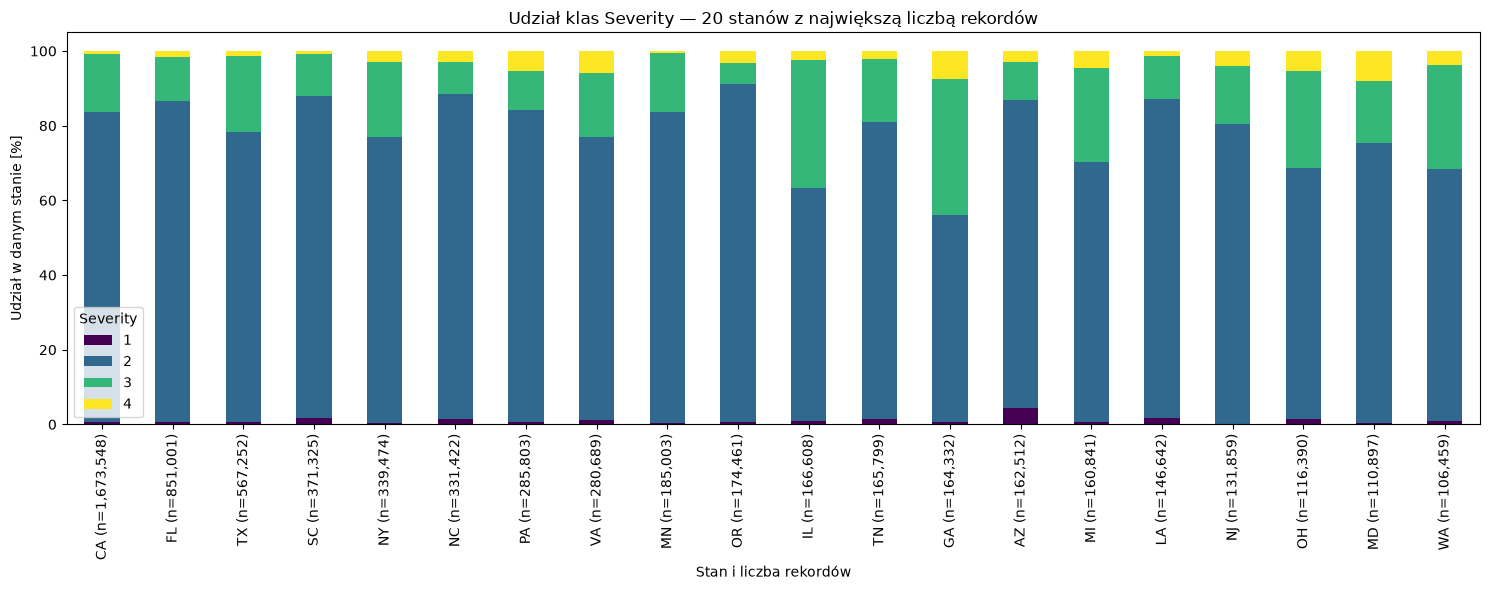

In [28]:
state_counts = pd.crosstab(final_data['State'], final_data['Severity'])
state_top = state_counts.sum(axis=1).nlargest(20).index
state_percent = state_counts.loc[state_top].div(state_counts.loc[state_top].sum(axis=1), axis=0) * 100
state_percent.index = [f"{state} (n={state_counts.loc[state].sum():,})" for state in state_top]
state_percent.plot.bar(stacked=True, figsize=(15, 6), colormap='viridis')
plt.title('Udział klas Severity — 20 stanów z największą liczbą rekordów')
plt.ylabel('Udział w danym stanie [%]')
plt.xlabel('Stan i liczba rekordów')
plt.legend(title='Severity')
plt.tight_layout()
plt.show()

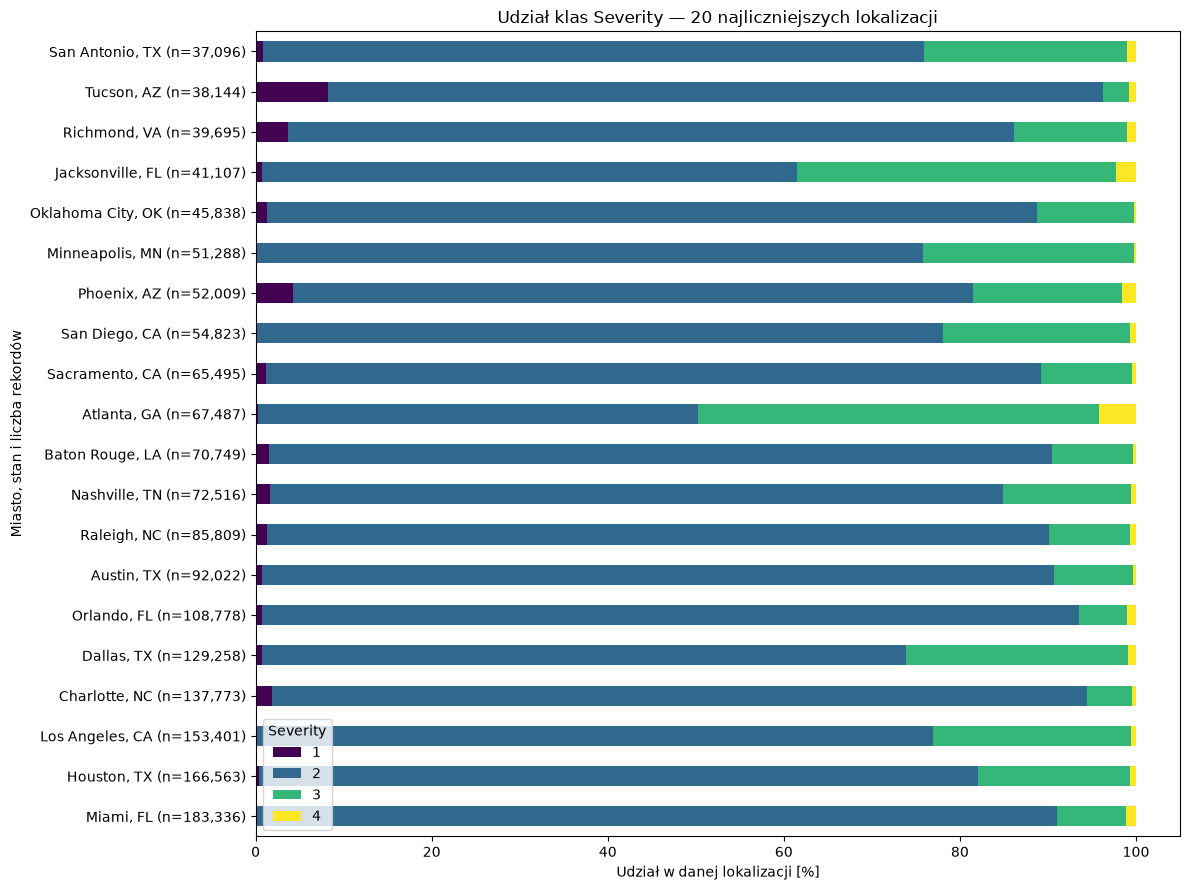

In [29]:
city_counts = final_data.groupby(['State', 'City', 'Severity'], observed=True).size().unstack('Severity', fill_value=0)
city_top = city_counts.sum(axis=1).nlargest(20).index
city_percent = city_counts.loc[city_top].div(city_counts.loc[city_top].sum(axis=1), axis=0) * 100
city_percent.index = [f"{city}, {state} (n={city_counts.loc[(state, city)].sum():,})" for state, city in city_top]
city_percent.plot.barh(stacked=True, figsize=(12, 9), colormap='viridis')
plt.title('Udział klas Severity — 20 najliczniejszych lokalizacji')
plt.xlabel('Udział w danej lokalizacji [%]')
plt.ylabel('Miasto, stan i liczba rekordów')
plt.legend(title='Severity')
plt.tight_layout()
plt.show()

**Obserwacje dotyczące struktury klas w lokalizacjach.** Klasa 2 dominuje w pokazanych stanach, lecz udziały klas istotnie się różnią. Georgia i Illinois mają większy udział klasy 3 niż np. Floryda czy Karolina Południowa. Wśród miast Atlanta wyróżnia się wysokim udziałem klasy 3, a Tucson — klasy 1. Lokalizacja może zatem zawierać informację przydatną do klasyfikacji; różnice mogą też odzwierciedlać źródła i sposób rejestracji danych.

# Warunki pogodowe a klasy Severity

#### Powiązane kolumny

In [30]:
weather_columns = ['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)',
                   'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition']
# Do analizy rozkładów używamy pomiarów źródłowych, bez imputacji średnią.
weather = df.loc[:, weather_columns + ['Severity']].copy()
weather.head()

,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Severity
0,36.900002,NaN,91.0,29.680000,10.0,Calm,NaN,0.02,Light Rain,3
1,37.900002,NaN,100.0,29.650000,10.0,Calm,NaN,0.00,Light Rain,2
2,36.000000,33.299999,100.0,29.670000,10.0,SW,3.5,NaN,Overcast,2
3,35.099998,31.000000,96.0,29.639999,9.0,SW,4.6,NaN,Mostly Cloudy,3
4,36.000000,33.299999,89.0,29.650000,6.0,SW,3.5,NaN,Mostly Cloudy,2


## Wartości odstające — porównanie przed i po filtrze IQR

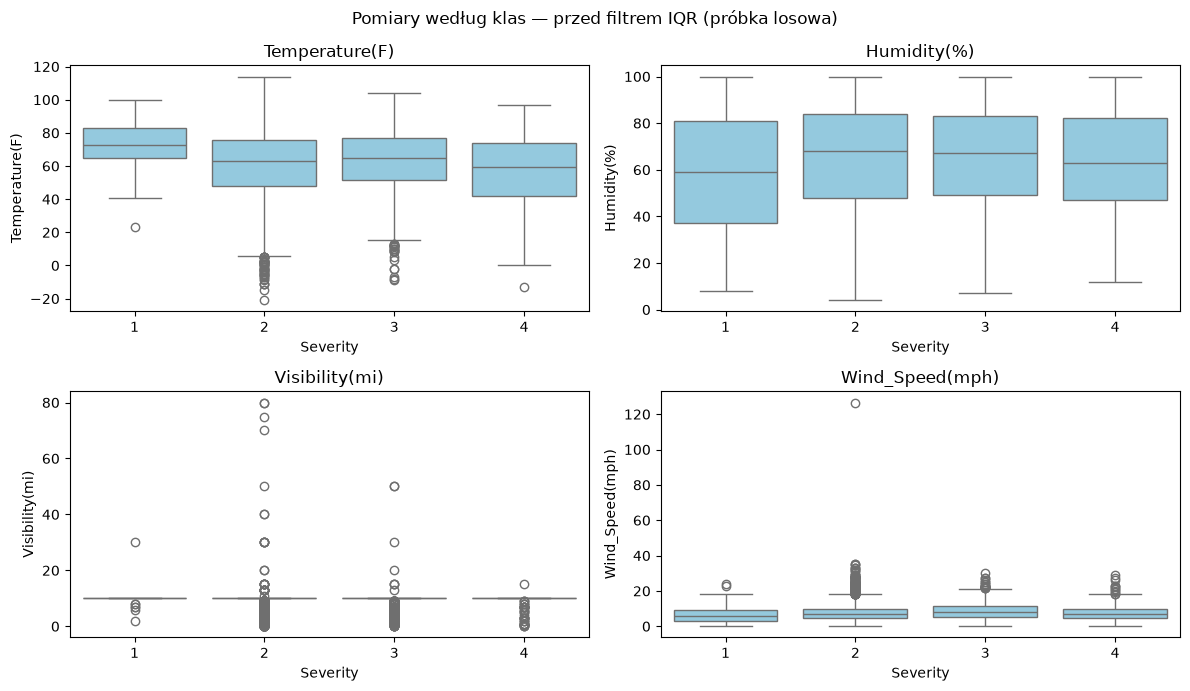

In [31]:
box_sample = weather.sample(n=min(10_000, len(weather)), random_state=42)
box_columns = ['Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)']
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, column in zip(axes.flat, box_columns):
    sns.boxplot(data=box_sample, x='Severity', y=column, ax=ax, color='skyblue')
    ax.set_title(column)
fig.suptitle('Pomiary według klas — przed filtrem IQR (próbka losowa)')
plt.tight_layout()
plt.show()

In [32]:
def remove_outliers(data, name):
    q25, q75 = data[name].quantile([0.25, 0.75])
    margin = 1.5 * (q75 - q25)
    # Zachowujemy braki: raport dotyczy odrzucania zmierzonych wartości.
    return data.loc[data[name].isna() | data[name].between(q25 - margin, q75 + margin)]

In [33]:
# IQR jest wariantem porównawczym, a nie automatycznym czyszczeniem danych.
weather_iqr = weather
for column in ['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Wind_Speed(mph)']:
    weather_iqr = remove_outliers(weather_iqr, name=column)
iqr_audit = pd.DataFrame({
    'przed': weather['Severity'].value_counts(),
    'po_IQR': weather_iqr['Severity'].value_counts(),
}).fillna(0).astype(int).sort_index()
iqr_audit['usunięto_%'] = (1 - iqr_audit['po_IQR'] / iqr_audit['przed']) * 100
display(iqr_audit)
# Kolejne analizy nadal korzystają z weather, bez filtrowania IQR.

,przed,po_IQR,usunięto_%
Severity,,,
1,67366,58528,13.119378
2,6156981,5600396,9.039901
3,1299337,1218034,6.257268
4,204710,182691,10.756192


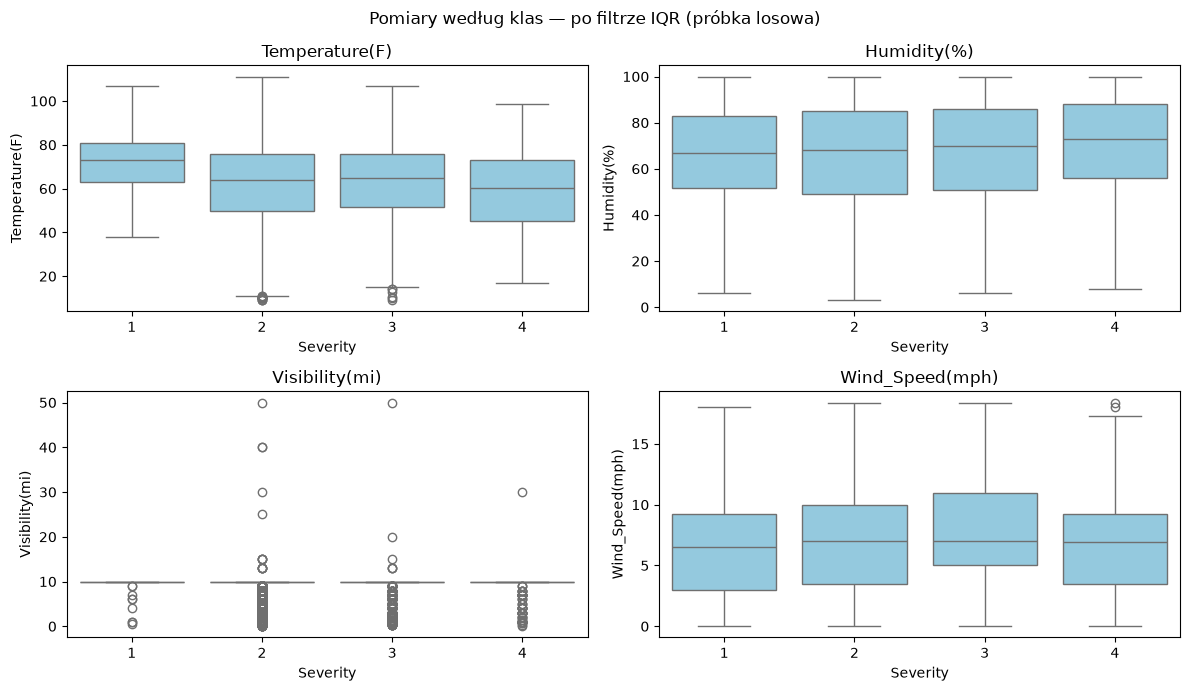

In [34]:
box_sample = weather_iqr.sample(n=min(10_000, len(weather_iqr)), random_state=42)
box_columns = ['Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)']
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, column in zip(axes.flat, box_columns):
    sns.boxplot(data=box_sample, x='Severity', y=column, ax=ax, color='skyblue')
    ax.set_title(column)
fig.suptitle('Pomiary według klas — po filtrze IQR (próbka losowa)')
plt.tight_layout()
plt.show()

**Wpływ filtra IQR.** Sekwencyjne filtrowanie pięciu pomiarów usuwa 13,12% rekordów klasy 1, 9,04% klasy 2, 6,26% klasy 3 i 10,76% klasy 4. Filtr nie działa więc jednakowo na wszystkie klasy i zmienia skład analizowanego zbioru. Ponieważ ekstremalne warunki mogą być rzeczywiste, wariant po IQR służy porównaniu; dalsze rozkłady pogody korzystają z danych przed tym filtrem. Pokazane boxploty opierają się na próbkach losowych, a nie na wszystkich rekordach.

## Temperatura (°F)

In [35]:
print("Unikalne wartości: ",weather["Temperature(F)"].nunique())
print("Brakujące wartości: ",weather["Temperature(F)"].isna().sum())

Unikalne wartości:  860
Brakujące wartości:  163853


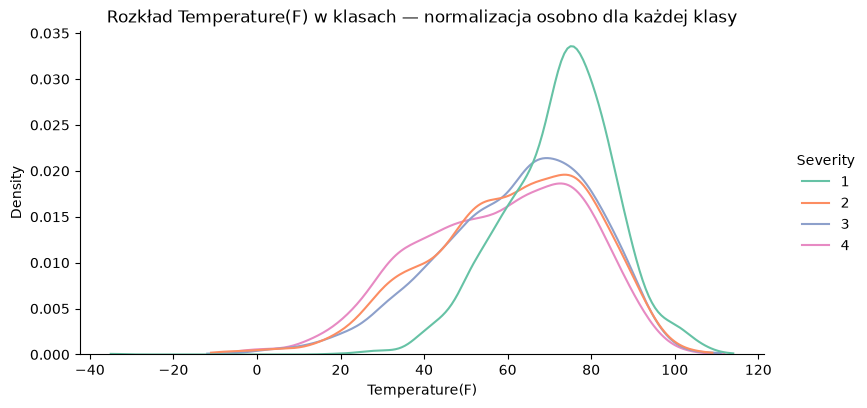

In [36]:
# Ograniczenie liczby obserwacji w każdej klasie chroni pamięć i rzadkie klasy.
kde_sample = pd.concat([
    group.sample(n=min(2000, len(group)), random_state=42)
    for _, group in weather[['Severity', 'Temperature(F)']].groupby('Severity', observed=True)
])
sns.displot(data=kde_sample, x='Temperature(F)', hue='Severity', kind='kde',
            common_norm=False, cut=0, palette='Set2', height=4, aspect=2)
plt.title('Rozkład Temperature(F) w klasach — normalizacja osobno dla każdej klasy')
plt.show()

## Temperatura odczuwalna (°F)

In [37]:
print("Unikalne wartości: ",weather["Wind_Chill(F)"].nunique())
print("Brakujące wartości: ",weather["Wind_Chill(F)"].isna().sum())
print("Średnia: ",weather["Wind_Chill(F)"].mean())

Unikalne wartości:  1001
Brakujące wartości:  1999019
Średnia:  58.251045


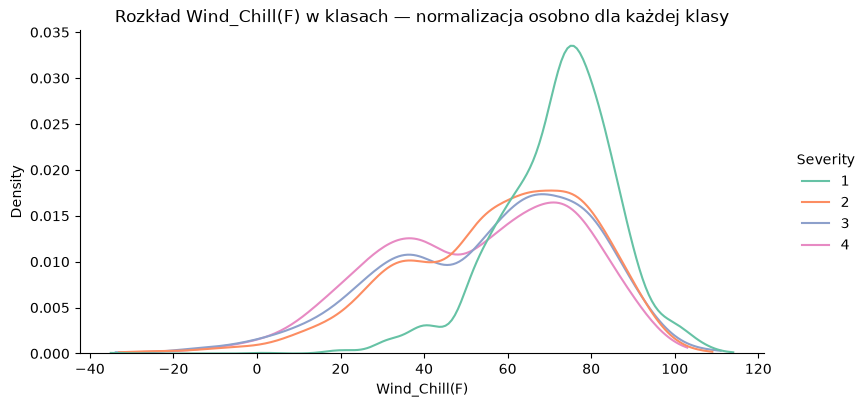

In [38]:
# Ograniczenie liczby obserwacji w każdej klasie chroni pamięć i rzadkie klasy.
kde_sample = pd.concat([
    group.sample(n=min(2000, len(group)), random_state=42)
    for _, group in weather[['Severity', 'Wind_Chill(F)']].groupby('Severity', observed=True)
])
sns.displot(data=kde_sample, x='Wind_Chill(F)', hue='Severity', kind='kde',
            common_norm=False, cut=0, palette='Set2', height=4, aspect=2)
plt.title('Rozkład Wind_Chill(F) w klasach — normalizacja osobno dla każdej klasy')
plt.show()

## Wilgotność (%)

In [39]:
print("Unikalne wartości: ",weather["Humidity(%)"].nunique())
print("Brakujące wartości: ",weather["Humidity(%)"].isna().sum())

Unikalne wartości:  100
Brakujące wartości:  174144


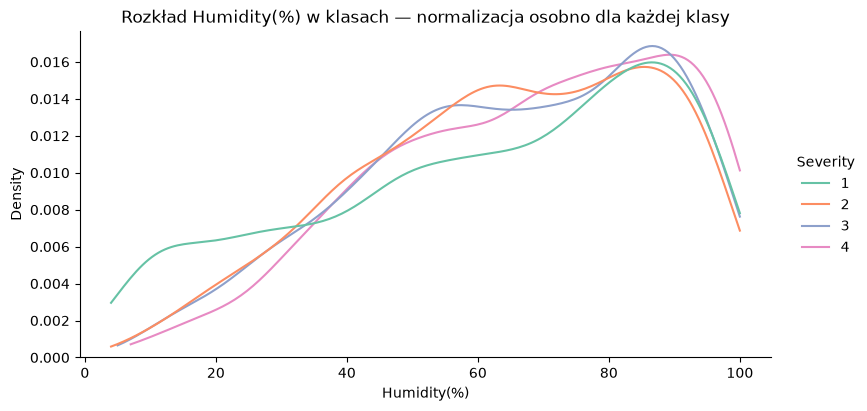

In [40]:
# Ograniczenie liczby obserwacji w każdej klasie chroni pamięć i rzadkie klasy.
kde_sample = pd.concat([
    group.sample(n=min(2000, len(group)), random_state=42)
    for _, group in weather[['Severity', 'Humidity(%)']].groupby('Severity', observed=True)
])
sns.displot(data=kde_sample, x='Humidity(%)', hue='Severity', kind='kde',
            common_norm=False, cut=0, palette='Set2', height=4, aspect=2)
plt.title('Rozkład Humidity(%) w klasach — normalizacja osobno dla każdej klasy')
plt.show()

## Ciśnienie (cale słupa rtęci)

In [41]:
print("Brakujące wartości: ",weather["Pressure(in)"].isna().sum())

Brakujące wartości:  140679


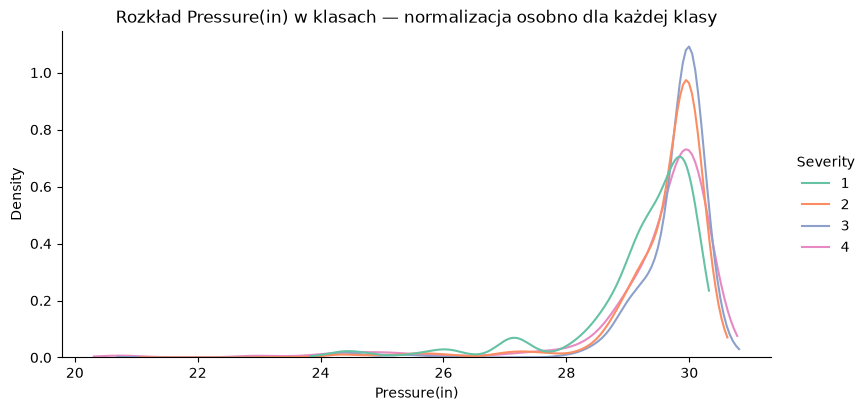

In [42]:
# Ograniczenie liczby obserwacji w każdej klasie chroni pamięć i rzadkie klasy.
kde_sample = pd.concat([
    group.sample(n=min(2000, len(group)), random_state=42)
    for _, group in weather[['Severity', 'Pressure(in)']].groupby('Severity', observed=True)
])
sns.displot(data=kde_sample, x='Pressure(in)', hue='Severity', kind='kde',
            common_norm=False, cut=0, palette='Set2', height=4, aspect=2)
plt.title('Rozkład Pressure(in) w klasach — normalizacja osobno dla każdej klasy')
plt.show()

## Widoczność (mile)

In [43]:
print("Unikalne wartości: ",weather["Visibility(mi)"].nunique())
print("Brakujące wartości: ",weather["Visibility(mi)"].isna().sum())

Unikalne wartości:  92
Brakujące wartości:  177098


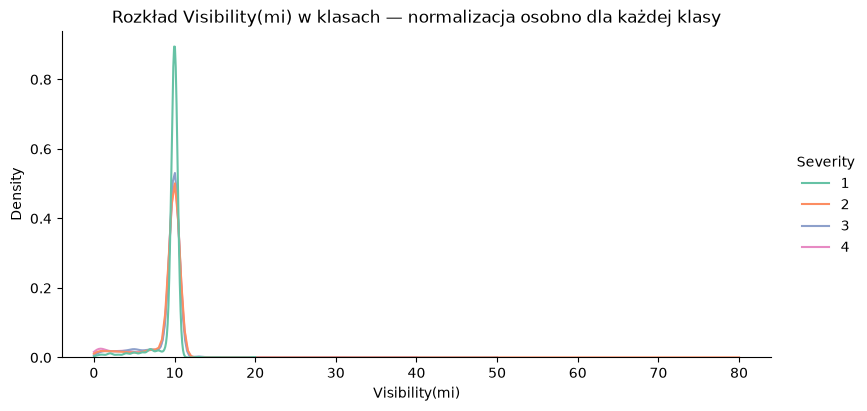

In [44]:
# Ograniczenie liczby obserwacji w każdej klasie chroni pamięć i rzadkie klasy.
kde_sample = pd.concat([
    group.sample(n=min(2000, len(group)), random_state=42)
    for _, group in weather[['Severity', 'Visibility(mi)']].groupby('Severity', observed=True)
])
sns.displot(data=kde_sample, x='Visibility(mi)', hue='Severity', kind='kde',
            common_norm=False, cut=0, palette='Set2', height=4, aspect=2)
plt.title('Rozkład Visibility(mi) w klasach — normalizacja osobno dla każdej klasy')
plt.show()

## Kierunek wiatru

In [45]:
print("Unikalne kategorie: ",weather["Wind_Direction"].unique())
print("Unikalne wartości: ",weather["Wind_Direction"].nunique())

Unikalne kategorie:  ['Calm', 'SW', 'SSW', 'WSW', 'WNW', ..., NaN, 'S', 'VAR', 'CALM', 'N']
Length: 25
Categories (24, str): ['CALM', 'Calm', 'E', 'ENE', ..., 'W', 'WNW', 'WSW', 'West']
Unikalne wartości:  24


C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2869920776.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Wind_Direction",
C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2869920776.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Wind_Direction",


<Axes: xlabel='Wind_Direction', ylabel='count'>

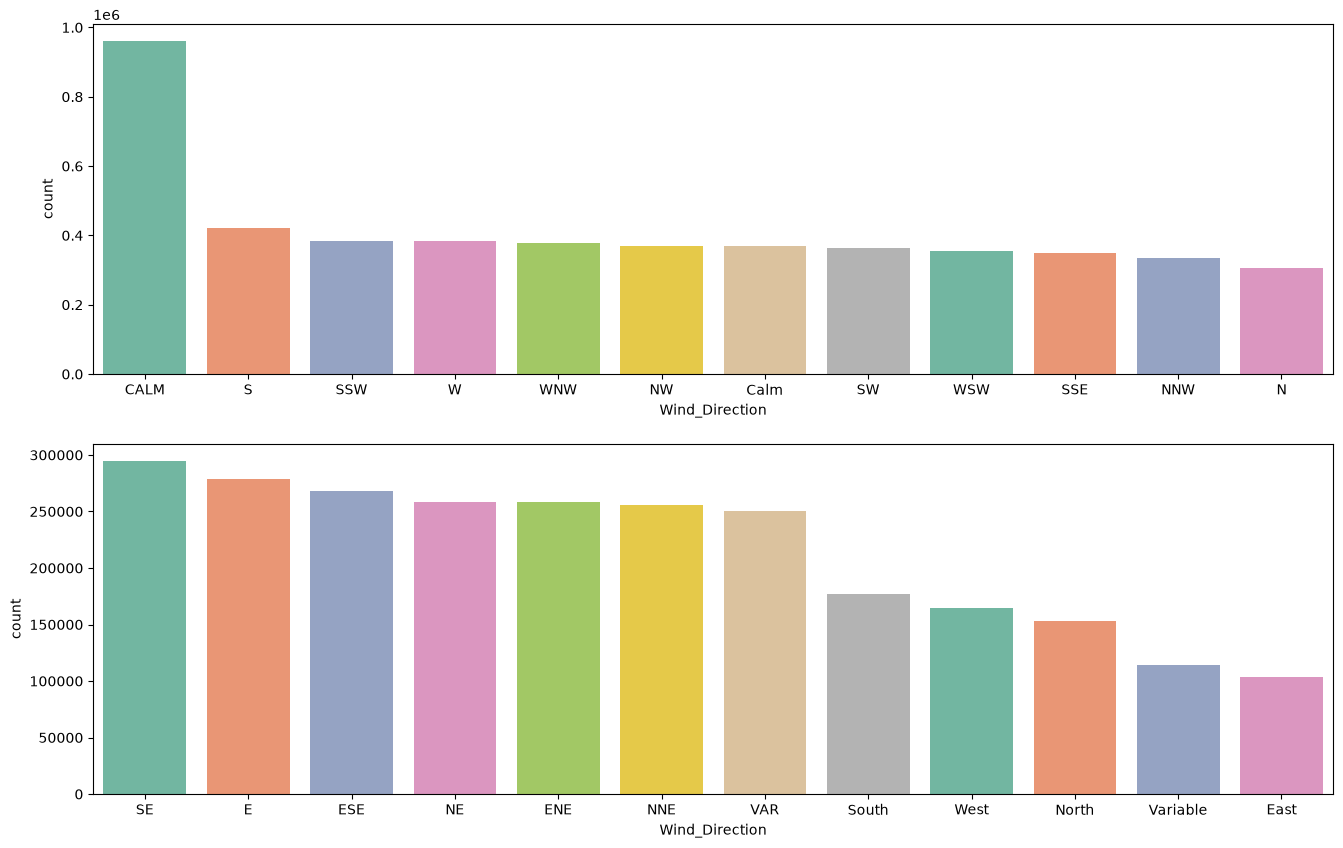

In [46]:
f,ax=plt.subplots(2,figsize=(16,10))
sns.countplot(x="Wind_Direction",
              data=weather,
              order=weather.Wind_Direction.value_counts().iloc[0:12].index,
              palette="Set2",
              ax=ax[0])
sns.countplot(x="Wind_Direction",
              data=weather,
              order=weather.Wind_Direction.value_counts().iloc[12:24].index,
              palette="Set2",
              ax=ax[1])

## Prędkość wiatru (mile/h)

In [47]:
print("Unikalne wartości: ",weather["Wind_Speed(mph)"].nunique())

Unikalne wartości:  184


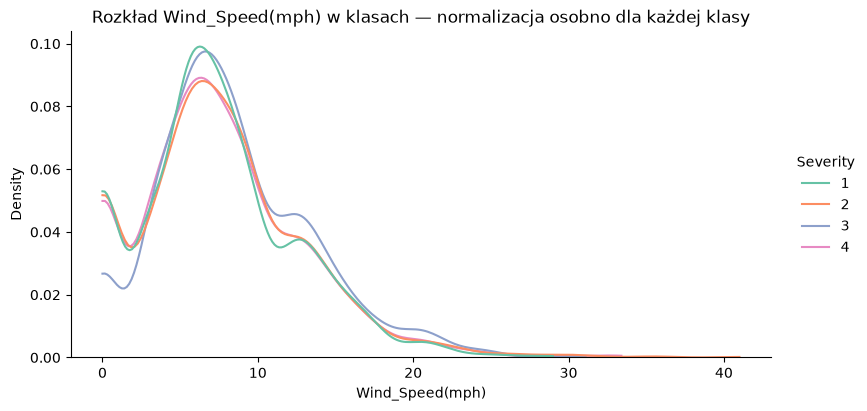

In [48]:
# Ograniczenie liczby obserwacji w każdej klasie chroni pamięć i rzadkie klasy.
kde_sample = pd.concat([
    group.sample(n=min(2000, len(group)), random_state=42)
    for _, group in weather[['Severity', 'Wind_Speed(mph)']].groupby('Severity', observed=True)
])
sns.displot(data=kde_sample, x='Wind_Speed(mph)', hue='Severity', kind='kde',
            common_norm=False, cut=0, palette='Set2', height=4, aspect=2)
plt.title('Rozkład Wind_Speed(mph) w klasach — normalizacja osobno dla każdej klasy')
plt.show()

## Warunki pogodowe

C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2546246270.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Weather_Condition",
C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2546246270.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Weather_Condition",
C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2546246270.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Weather_Condition",
C:\Users\lucri\AppData\Local\Temp\ipykernel_6108\2546246270.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprec

<Axes: xlabel='Weather_Condition', ylabel='count'>

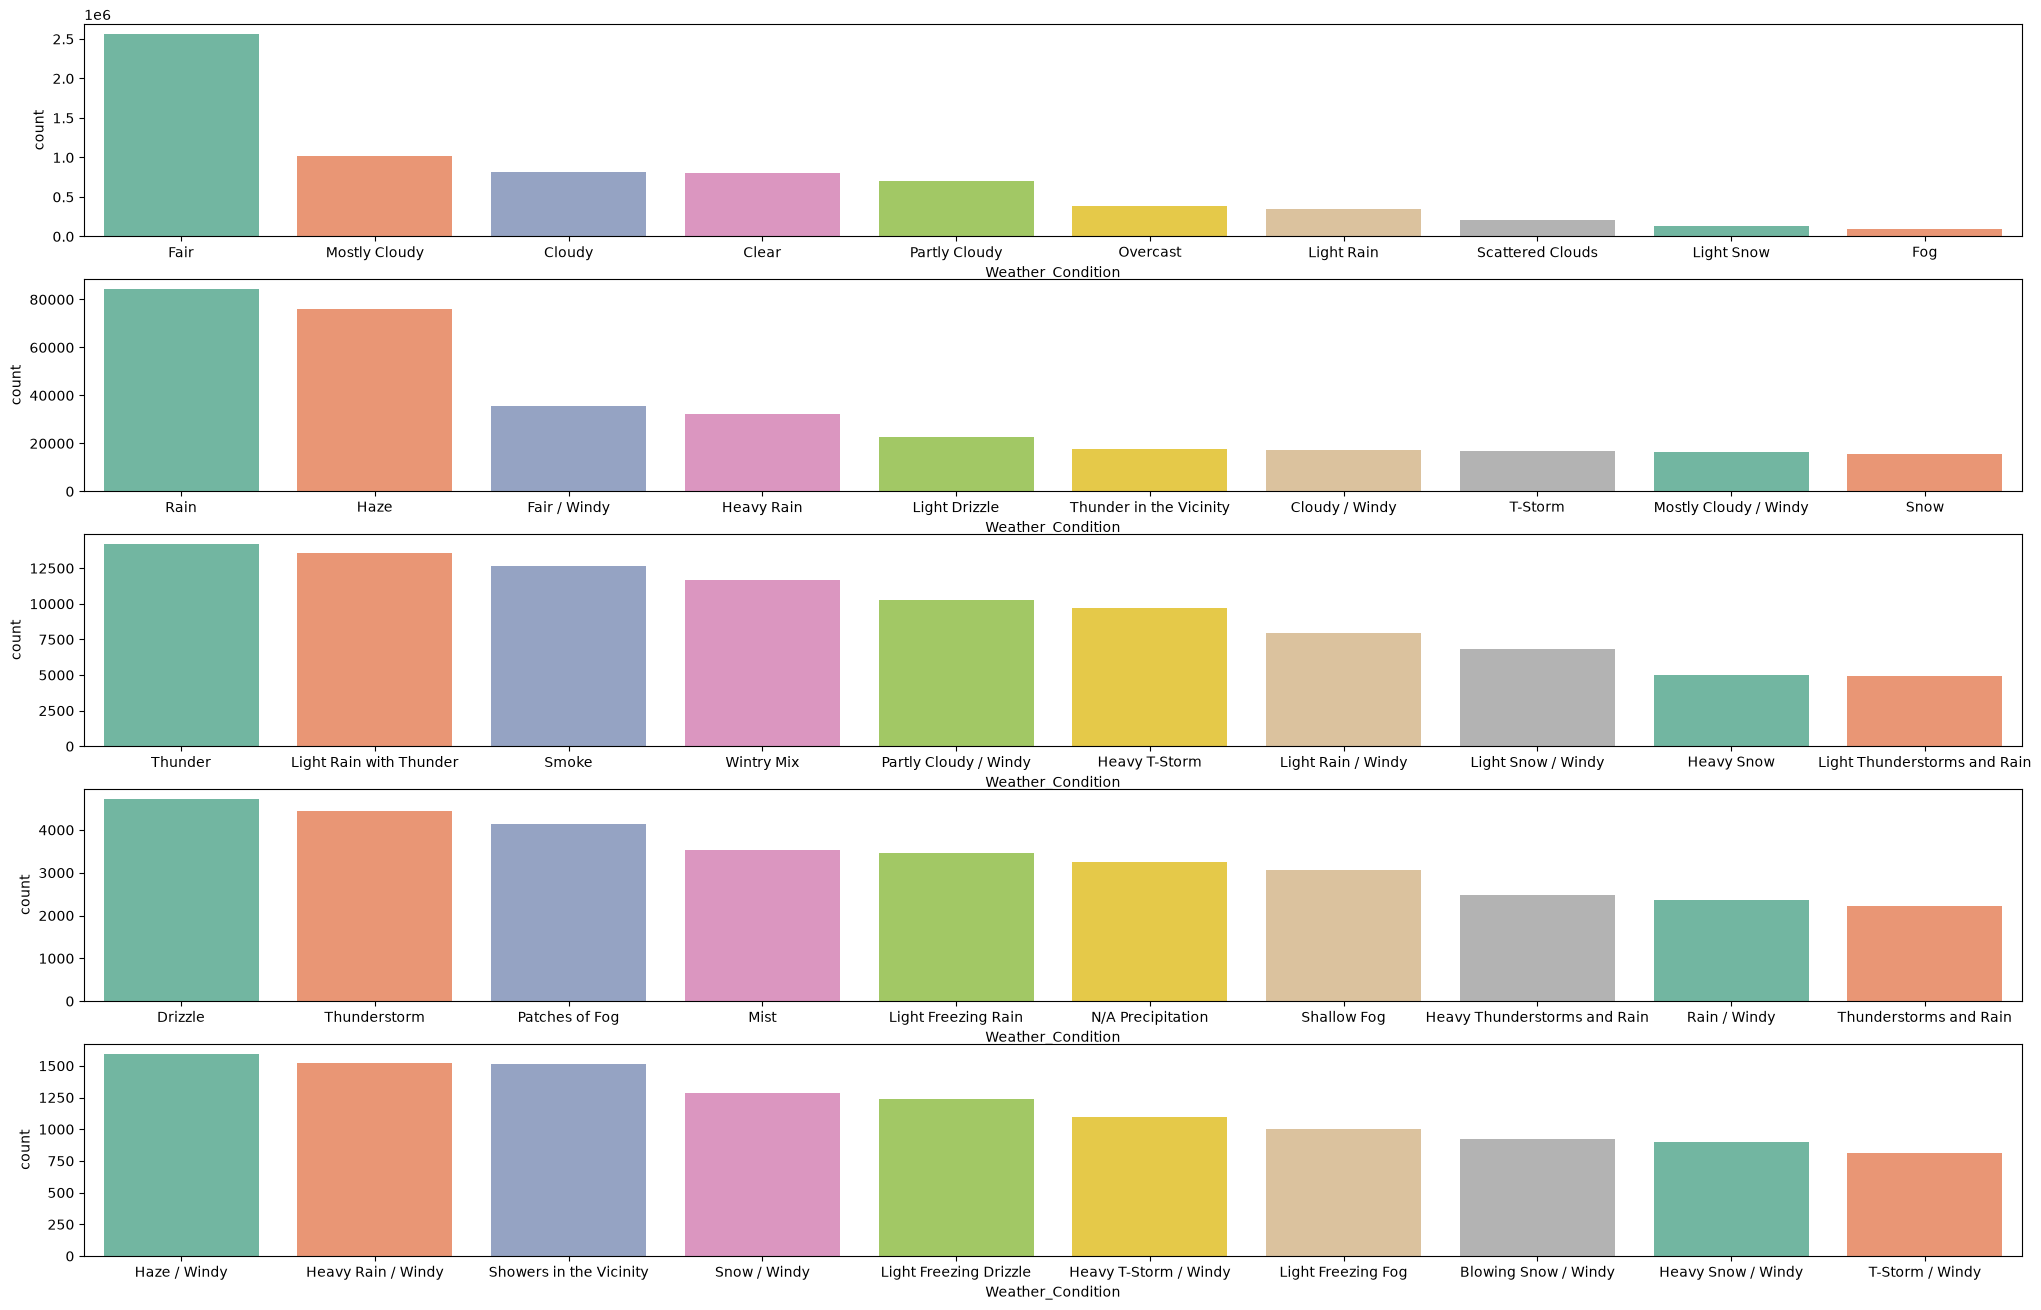

In [49]:
f,ax=plt.subplots(5,figsize=(25,16))
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[0:10].index,
              palette="Set2",
              ax=ax[0])
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[10:20].index,
              palette="Set2",
              ax=ax[1])
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[20:30].index,
              palette="Set2",
              ax=ax[2])
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[30:40].index,
              palette="Set2",
              ax=ax[3])
sns.countplot(x="Weather_Condition",
              data=weather,
              order=weather.Weather_Condition.value_counts().iloc[40:50].index,
              palette="Set2",
              ax=ax[4])

# Infrastruktura a klasy Severity

#### Powiązane kolumny

In [50]:
location = final_data.iloc[:, 26:39]
location.head()

,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False


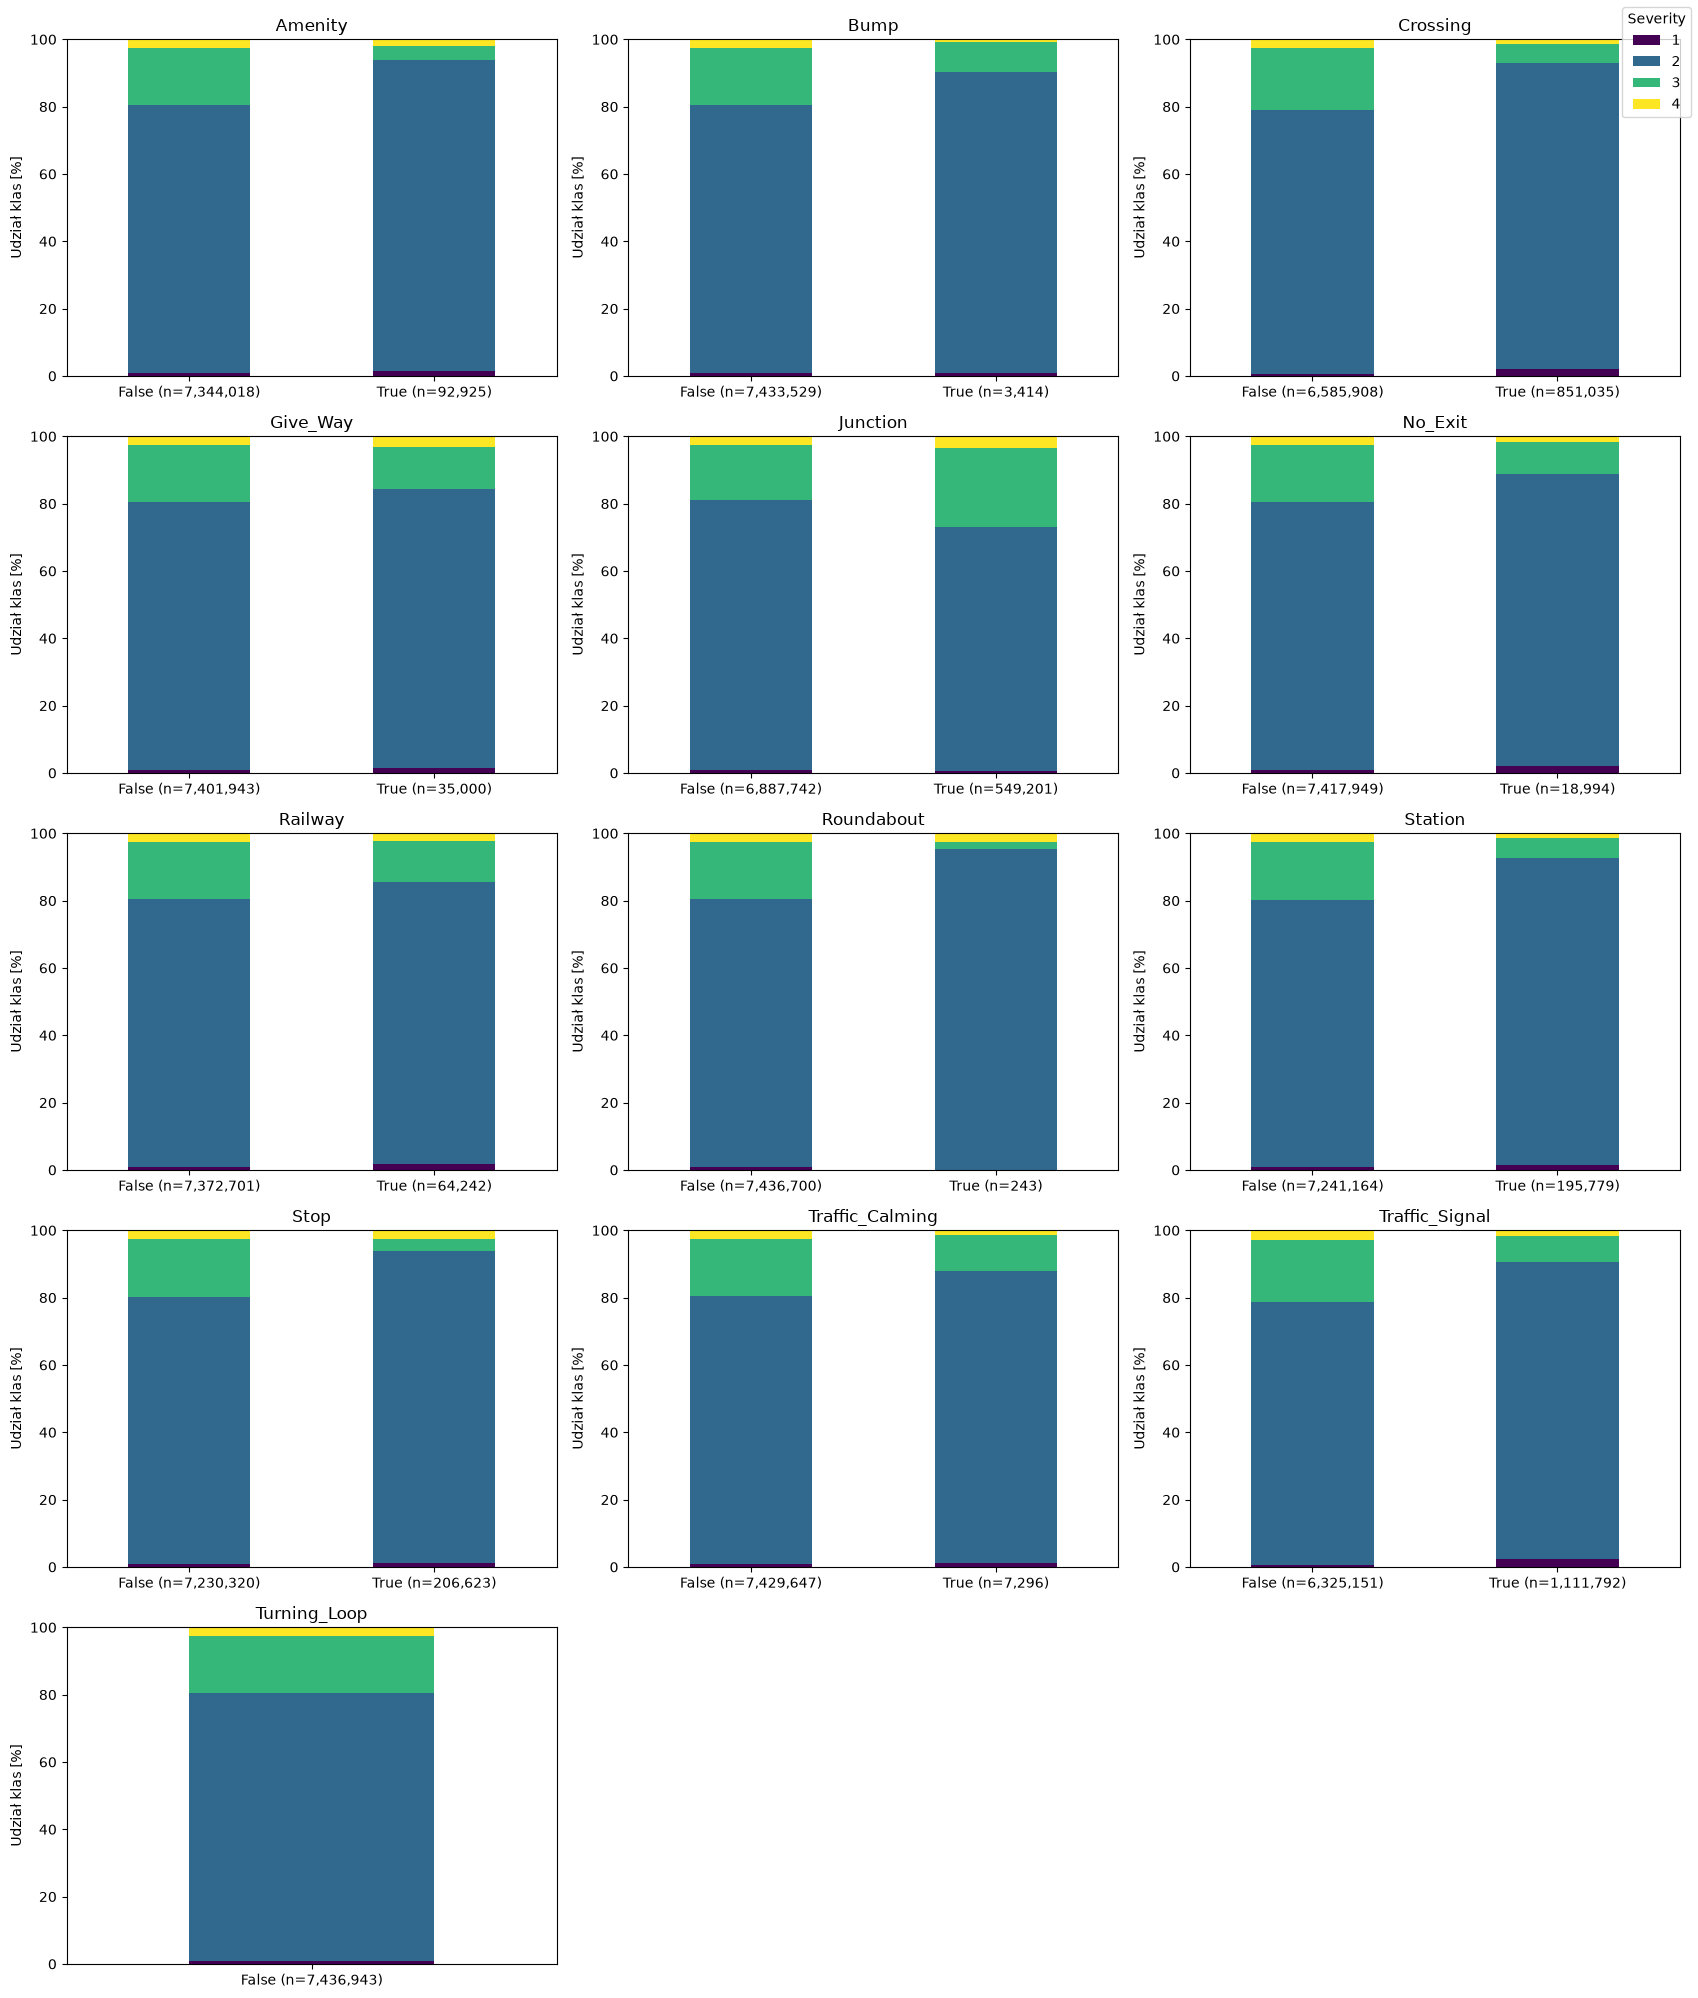

In [51]:
infrastructure_columns = list(location.columns)
fig, axes = plt.subplots(5, 3, figsize=(17, 20))
for ax, column in zip(axes.flat, infrastructure_columns):
    counts = pd.crosstab(final_data[column], final_data['Severity'])
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    percentages.index = [f'{value} (n={counts.loc[value].sum():,})' for value in percentages.index]
    percentages.plot.bar(stacked=True, ax=ax, legend=False, colormap='viridis', rot=0)
    ax.set(title=column, xlabel='', ylabel='Udział klas [%]', ylim=(0, 100))
for ax in axes.flat[len(infrastructure_columns):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Severity', loc='upper right')
plt.tight_layout()
plt.show()

**Obserwacje dotyczące infrastruktury.** Przy `Crossing=True` i `Traffic_Signal=True` udział klasy 2 jest większy niż przy wartości `False`. Dla `Junction=True` widoczny jest natomiast większy udział klas 3 i 4. `Roundabout=True` występuje po czyszczeniu jedynie w 243 rekordach, więc porównanie tej grupy jest znacznie mniej stabilne. Wykresy opisują strukturę klas wśród zdarzeń, a nie wpływ infrastruktury na prawdopodobieństwo wystąpienia wypadku.

## Uzupełnienie EDA: jakość danych i zależności względem Severity

In [52]:
# Pełne dane do tabel; ograniczone próbki tylko do kosztownych wizualizacji.
category_columns = df.select_dtypes(include=['object', 'string', 'category', 'bool']).columns.difference(['ID', 'Description'])
category_rows = []
for column in category_columns:
    counts = df[column].value_counts(dropna=True)
    category_rows.append({
        'cecha': column, 'unikalne': df[column].nunique(),
        'najczęstsza': counts.index[0] if len(counts) else None,
        'udział_najczęstszej_%': 100 * counts.iloc[0] / counts.sum() if len(counts) else np.nan,
        'braki_%': 100 * df[column].isna().mean(),
    })
category_summary = pd.DataFrame(category_rows).set_index('cecha')
display(category_summary.sort_values('unikalne'))
print('Powtórzone identyfikatory ID:', df['ID'].duplicated().sum())
print('Cechy stałe:', df.columns[df.nunique(dropna=False) <= 1].tolist())
# Pokazujemy równoważne zapisy kierunków bez modyfikowania df.
wind_aliases = {'CALM': 'Calm', 'VAR': 'Variable', 'East': 'E', 'West': 'W', 'North': 'N', 'South': 'S'}
display(pd.DataFrame({'oryginał': df['Wind_Direction'].dropna().unique()}).assign(
    ujednolicona=lambda table: table['oryginał'].astype(str).replace(wind_aliases)))

,unikalne,najczęstsza,udział_najczęstszej_%,braki_%
cecha,,,,
Country,1,US,100.000000,0.000000
Turning_Loop,1,False,100.000000,0.000000
Bump,2,False,99.954531,0.000000
Amenity,2,False,98.753506,0.000000
Civil_Twilight,2,Day,73.919657,0.300787
Junction,2,False,92.607235,0.000000
Give_Way,2,False,99.526655,0.000000
Astronomical_Twilight,2,Day,82.769961,0.300787
Railway,2,False,99.133339,0.000000


Powtórzone identyfikatory ID: 0
Cechy stałe: ['Country', 'Turning_Loop']


,oryginał,ujednolicona
0,Calm,Calm
1,SW,SW
2,SSW,SSW
3,WSW,WSW
4,WNW,WNW
5,NW,NW
6,West,W
7,NNW,NNW
8,NNE,NNE
9,South,S


**Wnioski o jakości cech.** `Country` i `Turning_Loop` są stałe w całym zbiorze, więc nie rozróżniają obserwacji. `Roundabout`, `Bump` i `Traffic_Calming` są bardzo rzadkie. `Wind_Direction` zawiera równoważne zapisy, m.in. `Calm`/`CALM`, `Variable`/`VAR` oraz `West`/`W`; tabela pokazuje proponowane ujednolicenie, ale nie zmienia danych. Brak powtórzonych `ID` potwierdza unikalność identyfikatorów, lecz nie wyklucza wielokrotnego opisania tego samego zdarzenia pod różnymi identyfikatorami.

### Wpływ czyszczenia na liczebność klas

In [53]:
cleaning_audit = pd.DataFrame({
    'źródło_n': df['Severity'].value_counts(),
    'po_czyszczeniu_n': final_data['Severity'].value_counts(),
}).fillna(0).sort_index()
cleaning_audit['źródło_%'] = cleaning_audit['źródło_n'] / len(df) * 100
cleaning_audit['po_czyszczeniu_%'] = cleaning_audit['po_czyszczeniu_n'] / len(final_data) * 100
cleaning_audit['usunięto_w_klasie_%'] = (1 - cleaning_audit['po_czyszczeniu_n'] / cleaning_audit['źródło_n']) * 100
display(cleaning_audit.round(3))
print(f'Usunięte rekordy: {len(df) - len(final_data):,} ({100 * (1 - len(final_data) / len(df)):.2f}%)')
# Braki według klasy pozwalają sprawdzić, czy czyszczenie nie działa wybiórczo.
missing_by_class = df.groupby('Severity', observed=True)[weather_columns].agg(lambda values: values.isna().mean() * 100)
display(missing_by_class.round(2))

,źródło_n,po_czyszczeniu_n,źródło_%,po_czyszczeniu_%,usunięto_w_klasie_%
Severity,,,,,
1,67366,65311,0.872,0.878,3.051
2,6156981,5924583,79.667,79.664,3.775
3,1299337,1254889,16.813,16.874,3.421
4,204710,192160,2.649,2.584,6.131


Usunięte rekordy: 291,451 (3.77%)


,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition
Severity,,,,,,,,,
1,1.65,3.280000,1.85,1.18,1.39,1.80,2.01,5.810000,1.42
2,2.11,21.740000,2.25,1.81,2.25,2.34,6.48,24.200001,2.19
3,2.00,46.099998,2.10,1.72,2.35,1.80,11.55,49.290001,2.33
4,3.23,28.980000,3.39,2.87,3.62,3.28,10.23,33.860001,3.63


**Wpływ czyszczenia i braków na klasy.** Usunięto 291 451 rekordów (3,77%), pozostawiając 7 436 943 obserwacje. Największą względną stratę ma klasa 4 (6,13%); jej udział maleje z 2,649% do 2,584%. Globalne proporcje zmieniają się niewiele, ale usuwanie danych nie jest jednakowe dla klas. Szczególnie wyraźne różnice dotyczą braków temperatury odczuwalnej (3,28% w klasie 1 wobec 46,10% w klasie 3) i opadów (5,81% wobec 49,29%). Oznacza to, że interpretując pomiary trzeba uwzględnić ich różną dostępność, bez zakładania, że braki są losowe.

### Statystyki pomiarów w klasach — bez imputacji i filtra IQR

In [54]:
numeric_eda = ['Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)',
               'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'Distance(mi)']
display(df.groupby('Severity', observed=True)[numeric_eda].agg(['count', 'median', 'mean', 'std']).round(3))
display(df.groupby('Severity', observed=True)[numeric_eda].quantile([0.25, 0.75]).round(3))
# Próbka do wykresów: do 2000 rekordów z każdej klasy, bez zmiany danych źródłowych.
eda_sample = pd.concat([
    group[numeric_eda + ['Severity']].sample(n=min(2000, len(group)), random_state=42)
    for _, group in df[numeric_eda + ['Severity']].groupby('Severity', observed=True)
])

Temperature(F)                                  Wind_Chill(F)         \
                  count     median       mean        std         count median   
Severity                                                                        
1                 66256  73.000000  72.417999  13.654000         65157   73.0   
2               6026823  64.000000  61.547001  19.042999       4818547   62.0   
3               1273360  64.900002  62.201000  18.785000        700286   61.0   
4                198102  60.099998  58.141998  19.714001        145385   57.0   

                               Humidity(%)         ... Wind_Speed(mph)         \
               mean        std       count median  ...            mean    std   
Severity                                           ...                          
1         72.241997  14.114000       66117   67.0  ...           7.142  5.062   
2         58.577000  22.097000     6018354   67.0  ...           7.567  5.434   
3         55.726002  24.070000     1272015   67.0  ...           8.317  5.325   
4         53.342999  23.381001      197764   70.0  ...           7.656  5.605   

         Precipitation(in)                      Distance(mi)                \
                     count median   mean    std        count median   mean   
Severity                                                                     
1                    63450    0.0  0.005  0.052        67366  0.000  0.115   
2                  4667015    0.0  0.007  0.096      6156981  0.068  0.565   
3                   658955    0.0  0.017  0.187      1299337  0.000  0.424   
4                   135388    0.0  0.007  0.087       204710  0.473  1.496   

                 
            std  
Severity         
1         0.759  
2         1.567  
3         2.241  
4         3.489  

[4 rows x 32 columns]

Temperature(F)  Wind_Chill(F)  Humidity(%)  Pressure(in)  \
Severity                                                                  
1        0.25            64.0           64.0         42.0         29.04   
         0.75            81.0           81.0         84.0         29.90   
2        0.25            49.0           43.5         48.0         29.34   
         0.75            76.0           75.0         84.0         30.02   
3        0.25            50.0           37.0         49.0         29.59   
         0.75            76.0           75.0         84.0         30.07   
4        0.25            43.0           35.0         51.0         29.25   
         0.75            73.9           72.0         87.0         30.04   

               Visibility(mi)  Wind_Speed(mph)  Precipitation(in)  \
Severity                                                            
1        0.25            10.0              3.0                0.0   
         0.75            10.0             10.0                0.0   
2        0.25            10.0              4.6                0.0   
         0.75            10.0             10.0                0.0   
3        0.25            10.0              5.0                0.0   
         0.75            10.0             11.5                0.0   
4        0.25            10.0              4.6                0.0   
         0.75            10.0             10.4                0.0   

               Distance(mi)  
Severity                     
1        0.25         0.000  
         0.75         0.000  
2        0.25         0.000  
         0.75         0.524  
3        0.25         0.000  
         0.75         0.010  
4        0.25         0.151  
         0.75         1.419

**Porównanie pomiarów w klasach.** Mediana temperatury wynosi 73°F w klasie 1, 64°F w klasie 2, około 64,9°F w klasie 3 i 60,1°F w klasie 4. Różnice występują, lecz zakresy międzykwartylowe mocno się nakładają. Dla `Distance(mi)` klasa 4 ma medianę 0,473 mili i średnią 1,496 mili, wyższe niż pozostałe klasy. Mediana opadów wynosi zero we wszystkich klasach, a kwartyle widoczności 25% i 75% wynoszą wszędzie 10 mil — same te statystyki nie rozróżniają klas. Różnice nie dowodzą zależności przyczynowej ani przydatności predykcyjnej poza tym zbiorem.

### Histogramy: skala oryginalna i log1p (tylko wartości nieujemne)

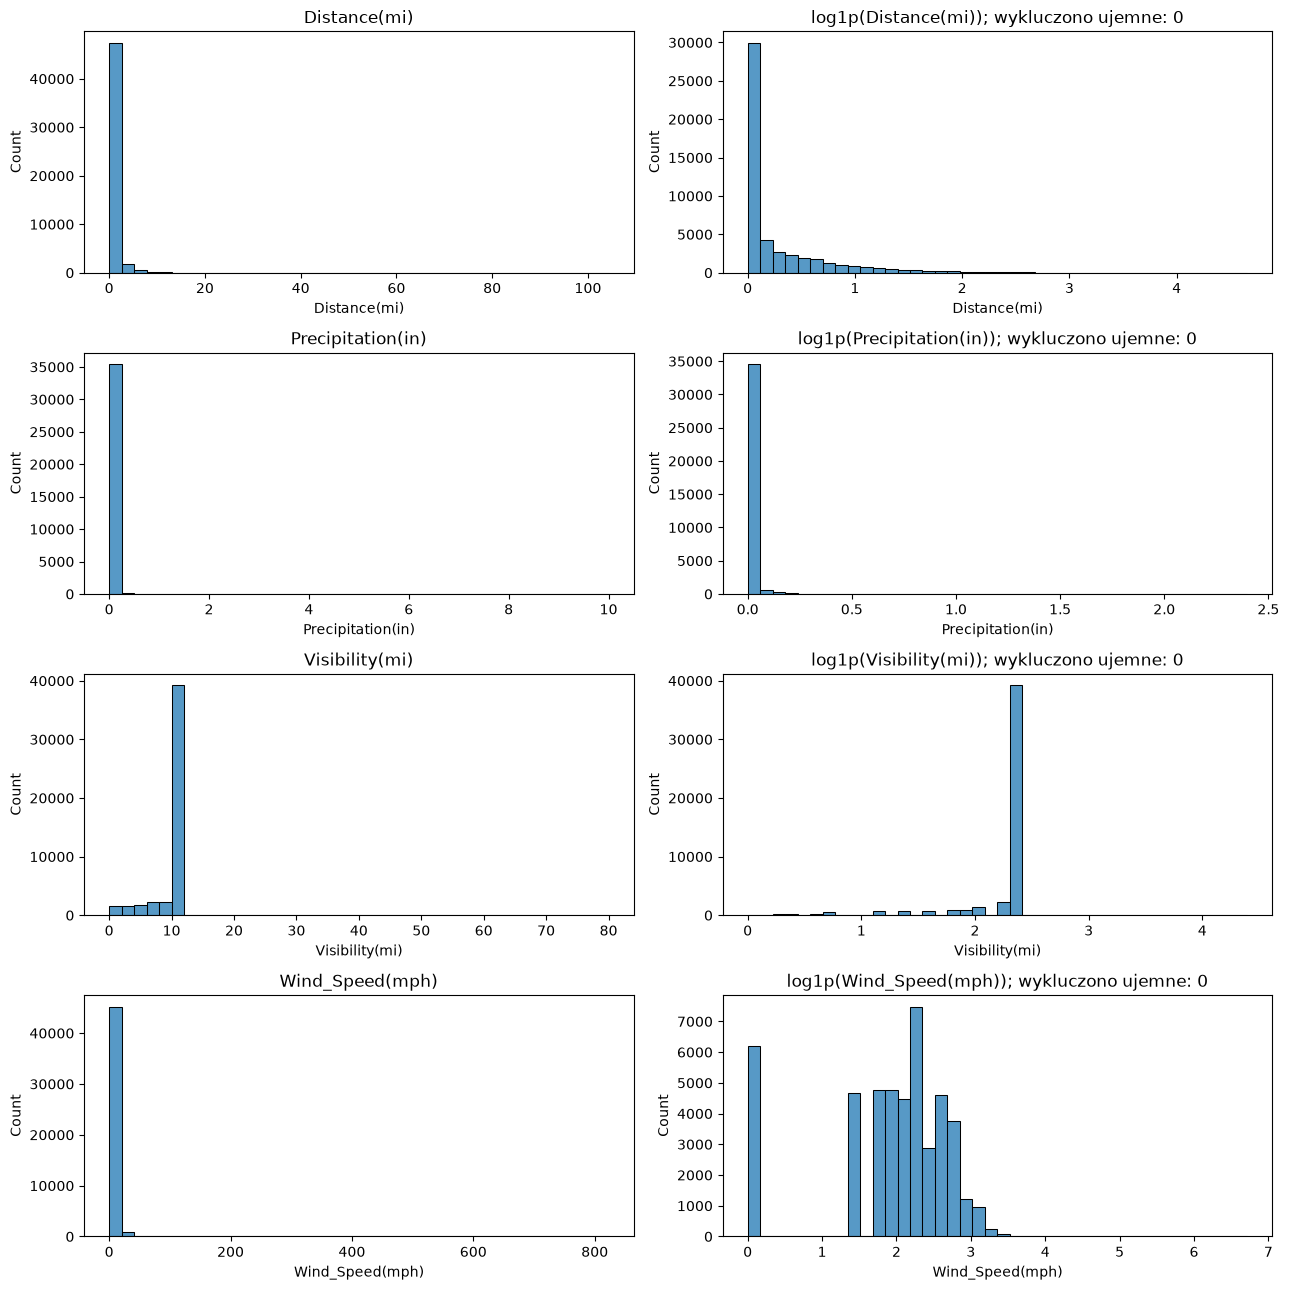

In [55]:
hist_columns = ['Distance(mi)', 'Precipitation(in)', 'Visibility(mi)', 'Wind_Speed(mph)']
hist_sample = df[hist_columns].sample(n=min(50_000, len(df)), random_state=42)
fig, axes = plt.subplots(len(hist_columns), 2, figsize=(13, 13))
for row, column in enumerate(hist_columns):
    values = hist_sample[column].dropna()
    sns.histplot(values, bins=40, ax=axes[row, 0])
    axes[row, 0].set_title(column)
    sns.histplot(np.log1p(values[values >= 0]), bins=40, ax=axes[row, 1])
    axes[row, 1].set_title(f'log1p({column}); wykluczono ujemne: {(values < 0).sum()}')
plt.tight_layout()
plt.show()

**Wnioski o rozkładach.** Statystyki pełnego zbioru potwierdzają silną skośność opadów i `Distance(mi)`: średnie przekraczają mediany, a nieliczne duże wartości rozciągają skale. Dla opadów oba kwartyle 25% i 75% wynoszą zero, dlatego warto odróżniać samo wystąpienie opadu od jego wielkości. Skala `log1p` ułatwia oglądanie długiego prawego ogona, ale nie usuwa zer ani nie weryfikuje wiarygodności ekstremów. Histogramy przedstawiają próbkę do 50 000 rekordów.

### Zależności między pomiarami — korelacja Spearmana

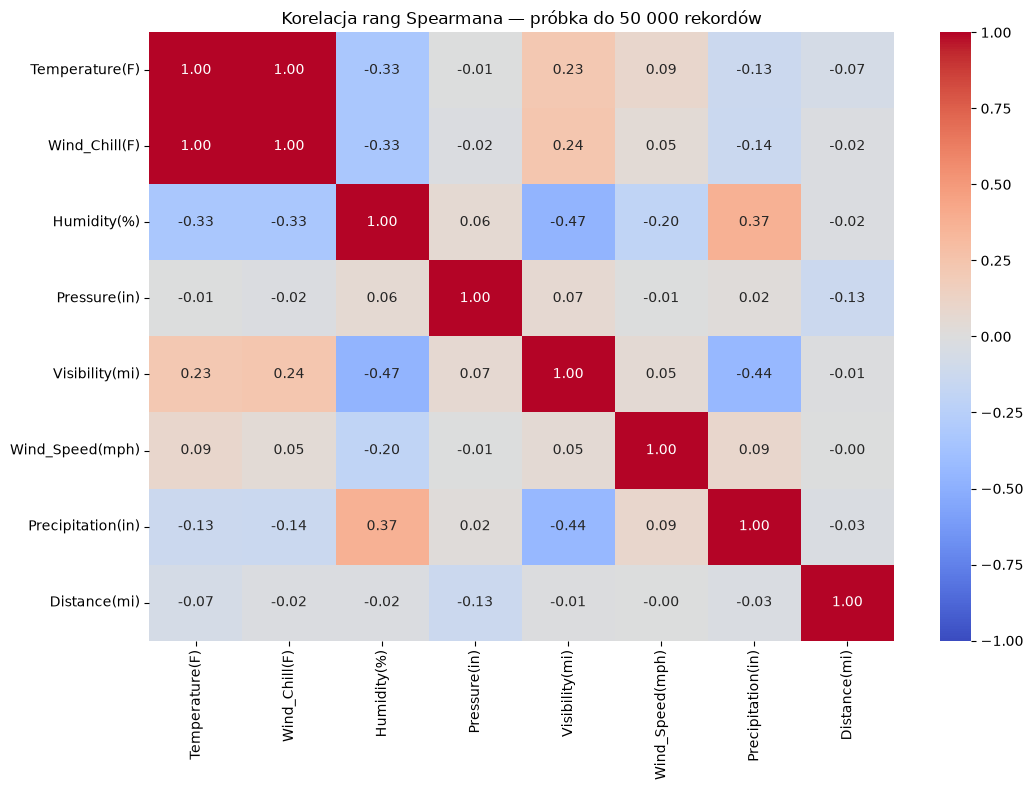

In [56]:
# Losowa próbka zachowuje naturalne proporcje klas; Severity nie jest pomiarem ciągłym.
corr_sample = df[numeric_eda].sample(n=min(50_000, len(df)), random_state=42)
correlation = corr_sample.corr(method='spearman')
plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Korelacja rang Spearmana — próbka do 50 000 rekordów')
plt.tight_layout()
plt.show()

**Wnioski z korelacji.** W losowej próbce korelacja Spearmana temperatury i temperatury odczuwalnej zaokrągla się do 1,00 — te cechy przekazują bardzo podobną informację w dostępnych parach pomiarów. Wilgotność jest ujemnie związana z widocznością (około −0,47), a opady z widocznością (około −0,44); opady i wilgotność mają korelację około 0,37. `Distance(mi)` ma słabe korelacje z pokazanymi pomiarami pogody. Korelacje obliczane są na dostępnych parach wartości i nie przesądzają o związku z `Severity`.

### Pogoda i pora dnia: procentowe rozkłady klas

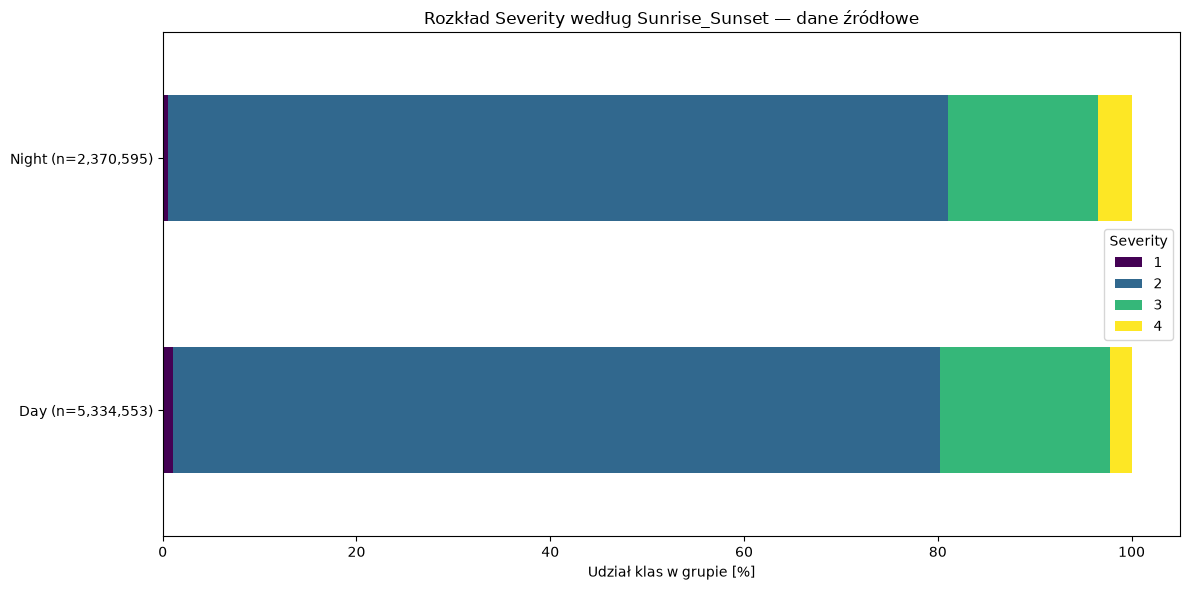

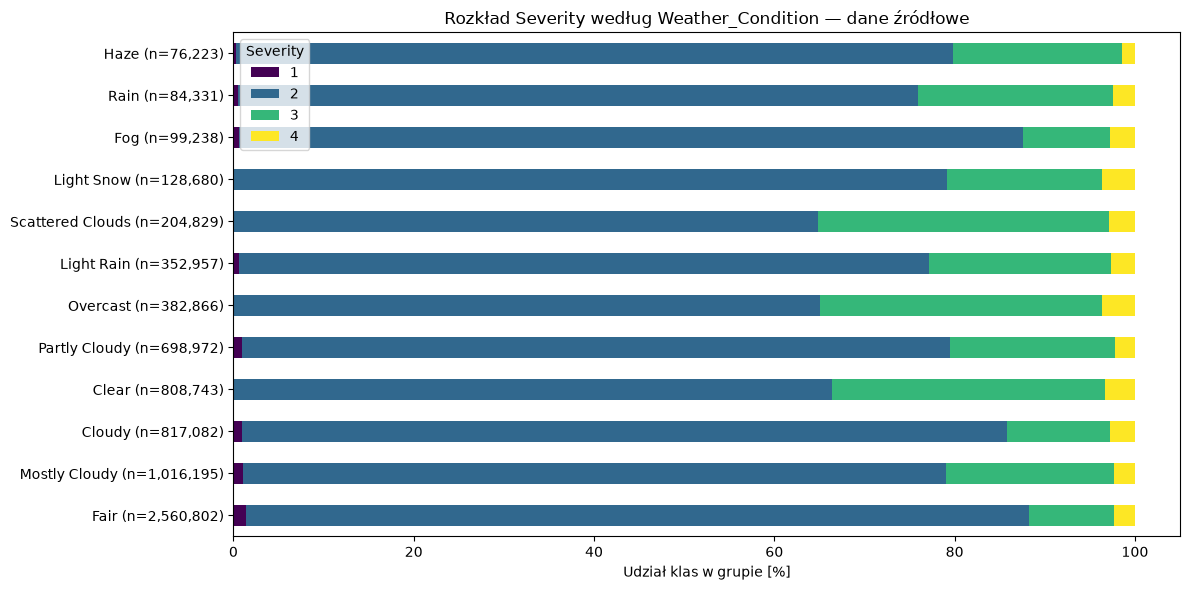

In [57]:
for column in ['Sunrise_Sunset', 'Weather_Condition']:
    counts = pd.crosstab(df[column], df['Severity'])
    top = counts.sum(axis=1).nlargest(12).index
    percentages = counts.loc[top].div(counts.loc[top].sum(axis=1), axis=0) * 100
    percentages.index = [f'{value} (n={counts.loc[value].sum():,})' for value in top]
    percentages.plot.barh(stacked=True, figsize=(12, 6), colormap='viridis')
    plt.title(f'Rozkład Severity według {column} — dane źródłowe')
    plt.xlabel('Udział klas w grupie [%]')
    plt.legend(title='Severity')
    plt.tight_layout()
    plt.show()

**Obserwacje dotyczące pogody i pory dnia.** W obu porach doby dominuje klasa 2. Dla nocy widoczny jest większy udział klasy 4, mimo mniejszej łącznej liczby rekordów niż za dnia. Wśród pokazanych kategorii pogodowych `Clear`, `Overcast` i `Scattered Clouds` mają większy udział klasy 3 niż `Fair`. Nie ma prostego wzorca, w którym każda kategoria niekorzystnej pogody oznacza większy udział wyższych klas. Różnice mogą być powiązane także z lokalizacją, okresem i źródłem danych; sam wykres nie pozwala ich rozdzielić.

### Pokrycie czasu oraz średnia liczba rekordów na obserwowany dzień

Zakres dat: 2016-01-14 00:00:00 — 2023-03-31 00:00:00
Dni bez rekordów w tym zakresie: 62


,dni_z_rekordami,dni_w_zakresie,rekordy,średnia_na_dzień_z_rekordami
2016,325,353,397995.0,1224.600000
2017,365,365,694985.0,1904.068493
2018,365,365,865720.0,2371.835616
2019,365,365,925134.0,2534.613699
2020,366,366,1131501.0,3091.532787
2021,363,365,1504772.0,4145.377410
2022,350,365,1681532.0,4804.377143
2023,73,90,235304.0,3223.342466


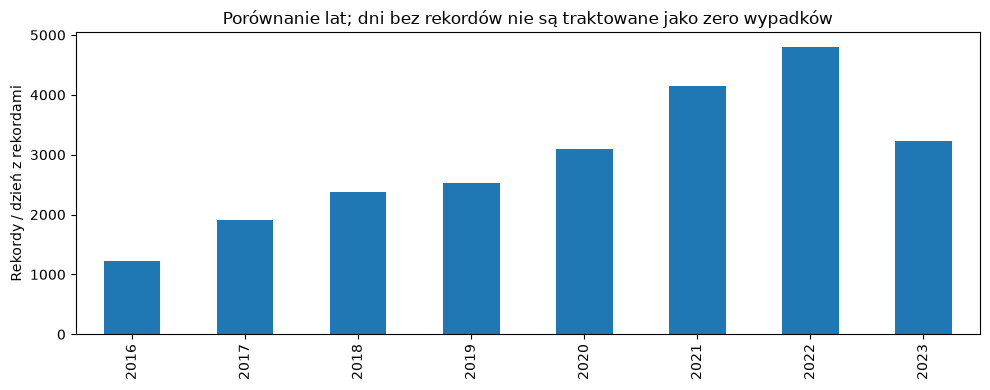

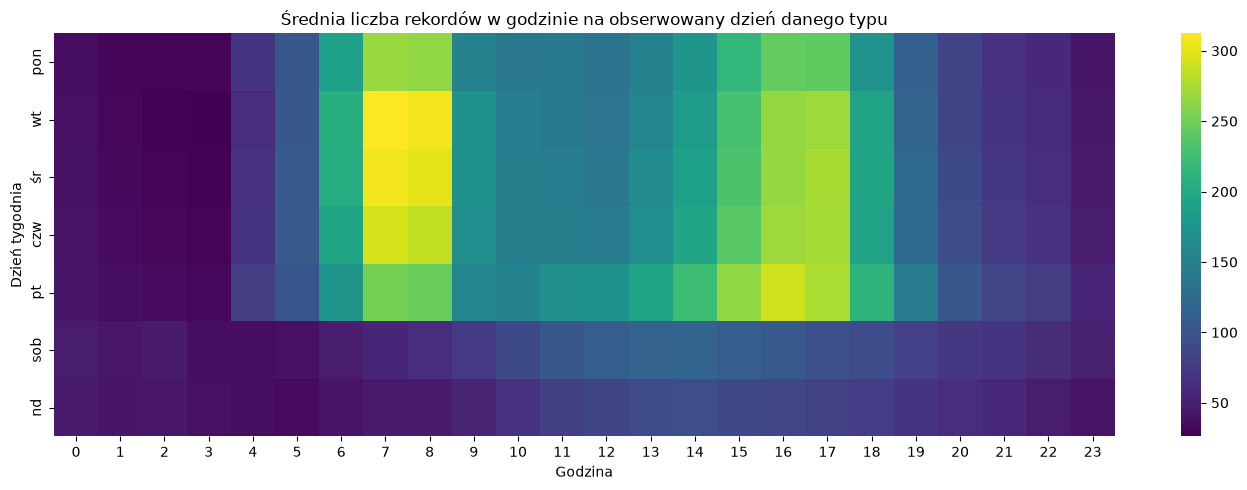

Severity,1,2,3,4,liczebność
Hour,,,,,
0,370,89221,10291,6730,106612
1,252,78737,8592,4584,92165
2,468,74003,9399,4647,88517
3,438,65181,9506,4649,79774
4,2549,117416,27256,5484,152705
5,2931,171489,36963,6886,218269
6,5188,306330,70300,8134,389952
7,8526,452358,97213,9422,567519
8,8808,443704,96298,9311,558121


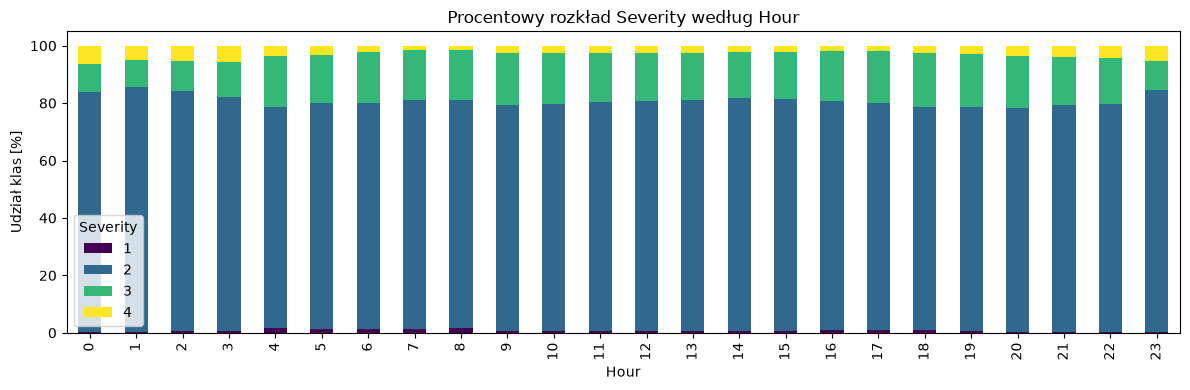

Severity,1,2,3,4,liczebność
Weekday,,,,,
0,11153,930824,195788,29123,1166888
1,12096,996656,206905,29769,1245426
2,12772,1015009,208922,29955,1266658
3,13039,1016265,210930,29982,1270216
4,11731,1053409,220131,30996,1316267
5,2349,502319,112577,21783,639028
6,2171,410101,99636,20552,532460


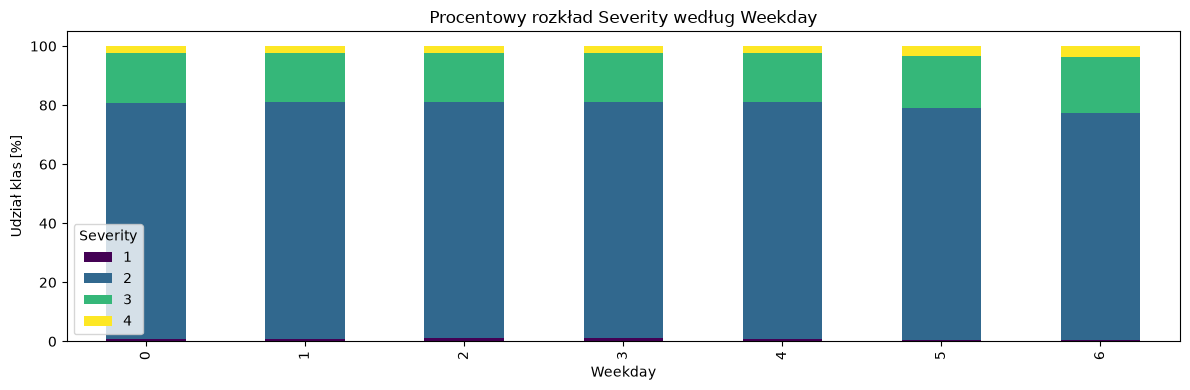

In [58]:
daily_counts = final_data.groupby(final_data['Start_Time'].dt.floor('D')).size()
calendar = pd.date_range(daily_counts.index.min(), daily_counts.index.max(), freq='D')
coverage = daily_counts.reindex(calendar)
print('Zakres dat:', calendar.min(), '—', calendar.max())
print('Dni bez rekordów w tym zakresie:', coverage.isna().sum())
annual_coverage = coverage.groupby(coverage.index.year).agg(['count', 'size', 'sum', 'mean'])
annual_coverage.columns = ['dni_z_rekordami', 'dni_w_zakresie', 'rekordy', 'średnia_na_dzień_z_rekordami']
display(annual_coverage)
annual_coverage['średnia_na_dzień_z_rekordami'].plot.bar(figsize=(10, 4))
plt.ylabel('Rekordy / dzień z rekordami')
plt.title('Porównanie lat; dni bez rekordów nie są traktowane jako zero wypadków')
plt.tight_layout()
plt.show()
hour_weekday = pd.crosstab(final_data['Weekday'], final_data['Hour']).reindex(index=range(7), columns=range(24), fill_value=0)
weekday_days = daily_counts.groupby(daily_counts.index.day_of_week).size().reindex(range(7), fill_value=0)
plt.figure(figsize=(14, 5))
sns.heatmap(hour_weekday.div(weekday_days.replace(0, np.nan), axis=0), cmap='viridis',
            yticklabels=['pon', 'wt', 'śr', 'czw', 'pt', 'sob', 'nd'])
plt.title('Średnia liczba rekordów w godzinie na obserwowany dzień danego typu')
plt.xlabel('Godzina')
plt.ylabel('Dzień tygodnia')
plt.tight_layout()
plt.show()
for column in ['Hour', 'Weekday']:
    counts = pd.crosstab(final_data[column], final_data['Severity'])
    display(counts.assign(liczebność=counts.sum(axis=1)))
    (counts.div(counts.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, figsize=(12, 4), colormap='viridis')
    plt.title(f'Procentowy rozkład Severity według {column}')
    plt.ylabel('Udział klas [%]')
    plt.tight_layout()
    plt.show()

**Wnioski dotyczące czasu.** Po czyszczeniu zakres obejmuje 14.01.2016–31.03.2023; wewnątrz niego są 62 dni bez rekordów. Rok 2023 obejmuje tylko początek roku, a liczba dni z rekordami różni się między latami. Średnia liczba rekordów na dzień z rekordami rośnie od około 1225 w 2016 r. do 4804 w 2022 r.; nie dowodzi to wzrostu ryzyka, ponieważ mogła zmieniać się kompletność rejestracji.

Najwięcej rekordów przypada na godziny 7–8 i 16–17. Piątek ma najwięcej obserwacji wśród dni tygodnia, a niedziela najmniej. Jednocześnie udział klasy 4 o północy wynosi około 6,31%, wobec 1,66% o godzinie 7; w niedzielę to około 3,86%, wobec 2,35% w piątek. Największa liczba zdarzeń nie oznacza więc największego udziału tej klasy. Adnotacje o dojazdach do pracy lub pandemii we wcześniejszych wykresach należy traktować jako hipotezy interpretacyjne, a nie potwierdzone przyczyny.

### Relacje wielowymiarowe — próbka z każdej klasy

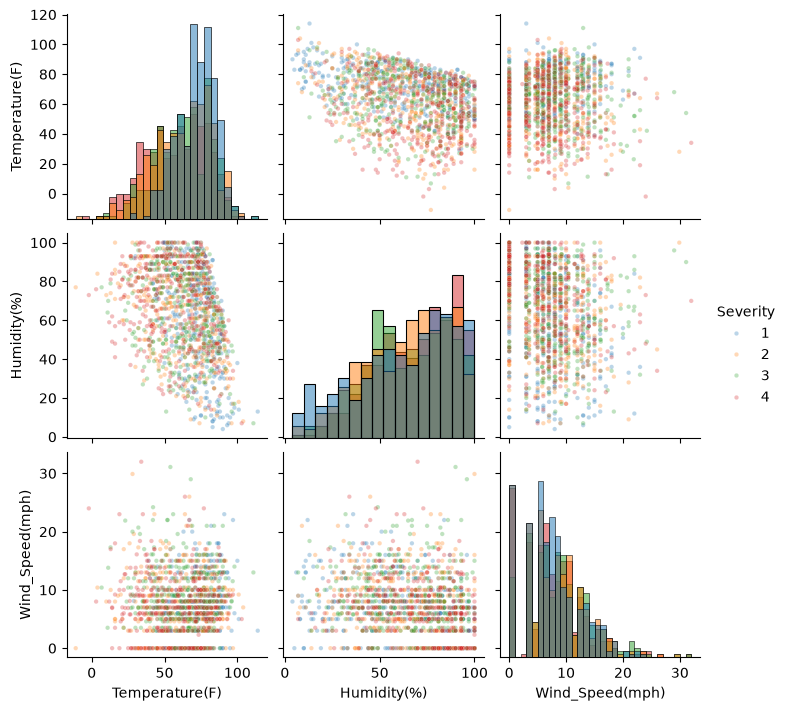

In [59]:
pair_columns = ['Temperature(F)', 'Humidity(%)', 'Wind_Speed(mph)']
pair_sample = pd.concat([
    group.sample(n=min(400, len(group)), random_state=42)
    for _, group in eda_sample.groupby('Severity', observed=True)
])[pair_columns + ['Severity']].dropna()
pair_sample['Severity'] = pair_sample['Severity'].astype(str)
if len(pair_sample) > 1:
    sns.pairplot(pair_sample, vars=pair_columns, hue='Severity', diag_kind='hist',
                 plot_kws={'s': 10, 'alpha': 0.3}, height=2.4)
    plt.show()

**Obserwacje wielowymiarowe.** Na próbce temperatury, wilgotności i prędkości wiatru klasy silnie się nakładają; nie widać prostego rozdzielenia ich pojedynczym progiem ani wyraźnie odseparowanych skupień. Klasa 1 jest bardziej skupiona przy wyższych temperaturach, zgodnie z medianami z pełnego zbioru. Widoczne pionowe i poziome pasma wskazują na powtarzalne, dyskretne wartości pomiarów. Wykres służy rozpoznaniu zależności; nie zastępuje oceny modelu.

Próbki z równym limitem na klasę służą porównaniu kształtów rozkładów, a nie oszacowaniu udziałów klas. Tabele liczebności i wykresy procentowe korzystają z pełnych danych. Zależności dotyczą zarejestrowanych zdarzeń; bez danych o natężeniu ruchu nie określają ryzyka wypadku ani związku przyczynowego.

### Podsumowanie wniosków z EDA

- Zbiór jest silnie niezbalansowany; dominacja klasy 2 wymaga oceny jakości osobno dla klas.
- Czyszczenie zmienia globalne proporcje nieznacznie, ale częściej usuwa rekordy klasy 4. Dostępność pomiarów pogody silnie zależy od klasy.
- Rozkłady klas różnią się między lokalizacjami, porami doby i grupami infrastruktury. Te zależności są kandydatami do weryfikacji podczas modelowania.
- Temperatura i temperatura odczuwalna niosą podobną informację; `Country` i `Turning_Loop` są stałe. Kategorie kierunku wiatru wymagają ujednolicenia.
- Skośność rozkładów oraz nierówny wpływ filtra IQR przemawiają za ostrożnym traktowaniem ekstremów. Zera, braki i rzeczywiste rzadkie pomiary mają różne znaczenie.
- EDA opisuje zarejestrowane zdarzenia. Bez informacji o ekspozycji na ruch i sposobie zbierania danych nie wyznacza ryzyka wypadku ani przyczyn obserwowanych różnic.

# Przygotowanie danych i walidacja bazowego modelu Severity

Dane źródłowe `df` pozostają bez zmian. Ponieważ celem jest przewidywanie przyszłych zdarzeń, podział trening/test jest chronologiczny, a walidacja używa `TimeSeriesSplit`. Dla ograniczenia czasu trening jest losową, warstwową próbą do 100 000 rekordów z wcześniejszego okresu; test to do 20 000 losowych rekordów z późniejszego okresu, bez stratyfikowania po etykietach. Strojenie wag klas odbywa się wyłącznie w CV; wybór maksymalizuje balanced accuracy, czyli średni recall klas obecnych w danym foldzie. Może to obniżyć precision i zwiększyć liczbę fałszywych alarmów. Test pozostaje nietknięty do końcowej oceny. Wyniki są oszacowaniem na próbie; sprawdź, czy każda cecha była dostępna w chwili przewidywania (zwłaszcza `Distance(mi)` i pomiary pogody).

In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    cohen_kappa_score,
    f1_score,
    make_scorer,
    mean_absolute_error,
    balanced_accuracy_score,
    recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET_COLUMN = "Severity"
CV_FOLDS = 5
TRAIN_SAMPLE_LIMIT = 100_000
TEST_SAMPLE_LIMIT = 20_000
RANDOM_STATE = 42

if TARGET_COLUMN not in df.columns:
    raise KeyError(f"Missing target column: {TARGET_COLUMN}")
if "Start_Time" not in df.columns:
    raise KeyError("Missing Start_Time required for time feature engineering")

numeric_candidates = [
    "Start_Lat", "Start_Lng", "Distance(mi)", "Temperature(F)",
    "Wind_Chill(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
    "Wind_Speed(mph)", "Precipitation(in)",
]
categorical_candidates = [
    "Source", "State", "Weather_Condition", "Wind_Direction", "Timezone",
    "Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight",
    "Astronomical_Twilight",
]
binary_candidates = [
    "Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
    "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming",
    "Traffic_Signal", "Turning_Loop",
]

numeric_features = [column for column in numeric_candidates if column in df.columns]
categorical_features = [column for column in categorical_candidates if column in df.columns]
categorical_features += [column for column in binary_candidates if column in df.columns]
model_feature_columns = numeric_features + categorical_features
if not model_feature_columns:
    raise ValueError("No model input features were found")

y_all = df.loc[df[TARGET_COLUMN].notna(), TARGET_COLUMN]
start_time_all = pd.to_datetime(
    df.loc[y_all.index, "Start_Time"], errors="coerce", format="mixed"
)
valid_time = start_time_all.notna()
y_all = y_all.loc[valid_time]
start_time_all = start_time_all.loc[valid_time]
if y_all.empty:
    raise ValueError("No rows have both a target and a valid Start_Time")

# Keep all future timestamps out of model selection and training.
time_cutoff = start_time_all.quantile(0.8)
train_pool_indices = start_time_all.index[start_time_all < time_cutoff]
test_pool_indices = start_time_all.index[start_time_all >= time_cutoff]
if train_pool_indices.empty or test_pool_indices.empty:
    raise ValueError("The chronological split produced an empty train or test period")

train_pool_y = y_all.loc[train_pool_indices]
if train_pool_y.nunique() < 2 or train_pool_y.value_counts().min() < CV_FOLDS:
    raise ValueError("The historical training period has too few examples per class")

if len(train_pool_indices) > TRAIN_SAMPLE_LIMIT:
    train_indices, _ = train_test_split(
        train_pool_indices.to_numpy(),
        train_size=TRAIN_SAMPLE_LIMIT,
        random_state=RANDOM_STATE,
        stratify=train_pool_y.to_numpy(),
    )
else:
    train_indices = train_pool_indices.to_numpy()

test_sample_size = min(TEST_SAMPLE_LIMIT, len(test_pool_indices))
if test_sample_size < len(test_pool_indices):
    test_indices, _ = train_test_split(
        test_pool_indices.to_numpy(),
        train_size=test_sample_size,
        random_state=RANDOM_STATE,
    )
else:
    test_indices = test_pool_indices.to_numpy()

train_indices = pd.Index(train_indices)
test_indices = pd.Index(test_indices)
train_indices = start_time_all.loc[train_indices].sort_values(kind="stable").index
test_indices = start_time_all.loc[test_indices].sort_values(kind="stable").index
model_indices = train_indices.append(test_indices)

# Work on a copy so the source dataframe and its columns remain unchanged.
X_model = df.loc[model_indices, model_feature_columns].copy()
y_model = y_all.loc[model_indices].copy()
start_time = start_time_all.loc[model_indices]
engineered_features = {
    "Hour_sin": np.sin(2 * np.pi * start_time.dt.hour / 24),
    "Hour_cos": np.cos(2 * np.pi * start_time.dt.hour / 24),
    "Weekday_sin": np.sin(2 * np.pi * start_time.dt.day_of_week / 7),
    "Weekday_cos": np.cos(2 * np.pi * start_time.dt.day_of_week / 7),
    "Month_sin": np.sin(2 * np.pi * (start_time.dt.month - 1) / 12),
    "Month_cos": np.cos(2 * np.pi * (start_time.dt.month - 1) / 12),
}
if set(engineered_features).intersection(df.columns):
    raise ValueError("Engineered feature names conflict with existing df columns")
for feature_name, values in engineered_features.items():
    X_model[feature_name] = values
numeric_features += list(engineered_features)

for column in numeric_features:
    X_model[column] = pd.to_numeric(X_model[column], errors="coerce")
for column in categorical_features:
    X_model[column] = X_model[column].astype("object").where(
        X_model[column].notna(), np.nan
    )

X_train = X_model.loc[train_indices]
X_test = X_model.loc[test_indices]
y_train = y_all.loc[train_indices]
y_test = y_all.loc[test_indices]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False)),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

# Keep preprocessing inside the estimator so each temporal fold fits it on past data only.
model_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        solver="saga", max_iter=2000, tol=1e-3, random_state=RANDOM_STATE
    )),
])
class_labels = sorted(y_train.unique())
macro_f1_scorer = make_scorer(
    f1_score, average="macro", labels=class_labels, zero_division=0
)
cv = TimeSeriesSplit(n_splits=CV_FOLDS)
cv_splits = list(cv.split(X_train))
fold_support = []
for fold_number, (fit_indices, validation_indices) in enumerate(cv_splits, start=1):
    validation_counts = y_train.iloc[validation_indices].value_counts()
    fold_support.append({
        "fold": fold_number,
        "train_end": start_time_all.loc[train_indices[fit_indices]].max(),
        "validation_start": start_time_all.loc[train_indices[validation_indices]].min(),
        "validation_end": start_time_all.loc[train_indices[validation_indices]].max(),
        **{f"Severity_{label}_n": int(validation_counts.get(label, 0)) for label in class_labels},
    })
display(pd.DataFrame(fold_support))

# Select class weighting on historical folds only; the future holdout is not used for tuning.
search = GridSearchCV(
    model_pipeline,
    param_grid={"classifier__class_weight": [None, "balanced"]},
    scoring={
        "f1_macro": macro_f1_scorer,
        "balanced_accuracy": "balanced_accuracy",
    },
    refit="balanced_accuracy",
    cv=cv_splits,
    n_jobs=1,
    error_score="raise",
    return_train_score=False,
)
search.fit(X_train, y_train)
cv_summary = pd.DataFrame(search.cv_results_)[[
    "param_classifier__class_weight",
    "mean_test_f1_macro",
    "std_test_f1_macro",
    "mean_test_balanced_accuracy",
    "std_test_balanced_accuracy",
]]
display(cv_summary.round(3))
print(f"Wybrana waga klas (maksymalizuje balanced accuracy): {search.best_params_['classifier__class_weight']}")

# The future holdout is used once, after CV has selected the weighting.
best_pipeline = search.best_estimator_
y_pred = best_pipeline.predict(X_test)
print("\nRaport klasyfikacji dla przyszłego okresu testowego:\n")
print(classification_report(
    y_test, y_pred, labels=class_labels, zero_division=0
))
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"Quadratic weighted kappa: {cohen_kappa_score(y_test, y_pred, weights='quadratic'):.3f}")
print(f"Średni błąd stopnia Severity (MAE): {mean_absolute_error(y_test, y_pred):.3f}")
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, normalize="true", cmap="Blues", values_format=".2f"
)
plt.title("Znormalizowana macierz pomyłek - zbiór testowy")
plt.tight_layout()
plt.show()

print("Source class counts:\n", y_all.value_counts().sort_index())
print(f"Chronological cutoff: {time_cutoff}")
print(f"Training period: {start_time_all.loc[train_indices].min()} - {start_time_all.loc[train_indices].max()}")
print(f"Test period: {start_time_all.loc[test_indices].min()} - {start_time_all.loc[test_indices].max()}")
print(f"Training/test sample sizes: {len(y_train):,} / {len(y_test):,}")
print("Training class counts:\n", y_train.value_counts().sort_index())
print("Test class counts:\n", y_test.value_counts().sort_index())
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical/binary features: {len(categorical_features)}")
print(f"Chronological CV folds: {len(cv_splits)}")